# Credit Card Fraud Simulation: How SHAP-SMOTE Cleans, Processes, and Rebalances the Data
## Data Quality, Leak-Free Preprocessing, SHAP Attribution, Synthetic Oversampling, and Downstream Impact

> **Project:** Explainability-Aware Synthetic Oversampling (SHAP-SMOTE)

This notebook takes the **Credit Card Fraud Simulation** (28 PCA-style components `V1`–`V28`, ~2% fraud, 49:1)
through the complete SHAP-SMOTE pipeline and measures what changes at every step:
1. **Data Quality Audit and Cleaning** (missing values, infinities, duplicates, constant columns, outliers)
2. **Feature Separability** (which components carry the fraud signal)
3. **Leak-Free Split and Scaling** (`StandardScaler` fit on the training fold only)
4. **SHAP Attribution** (Mean Absolute SHAP Values from a preliminary Random Forest)
5. **SHAP-Filtered SMOTE** and **SHAP-Weighted SMOTE** versus Classical SMOTE
6. **What Changed** (class counts, neighbour graphs, synthetic placement, realism, fidelity)
7. **Downstream Impact** (hold-out test and repeated leak-free cross-validation)
8. **Real Kaggle Data → Generated Datasets** (the same pipeline on 284,807 real transactions, written to CSV)

The simulator plants fraud on **7 hidden components** (each fraud is shifted ±2.5–4σ, with a random sign) and leaves
the other 21 as pure noise. Because the ground truth is known, we can check whether SHAP actually finds the signal.

**Output of this notebook:** Sections 14–17 run the pipeline on the real ULB/Kaggle credit card fraud data and write the rebalanced training sets (real rows + new synthetic fraud rows, flagged by `is_synthetic`) to `data/credit_card/generated/`.

In [1]:
import sys
import warnings
from pathlib import Path

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'oversampling').is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from scipy.stats import ks_2samp, wasserstein_distance

import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.base import clone
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, confusion_matrix

from src.pipeline.datasets import load_benchmark_dataset
from src.pipeline.leak_free_cv import LeakFreePipeline
from src.oversampling import (
    compute_masv_weights, SHAPFilteredSMOTE, SHAPWeightedSMOTE, ClassicalSMOTE, RawNoBalancing,
)
from src.evaluation.metrics import evaluate_multi_dimensional_metrics
from src.evaluation.fidelity import compute_synthetic_fidelity
# src.evaluation switches matplotlib to the headless 'Agg' backend; restore inline plotting
%matplotlib inline

sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams.update({
    'figure.autolayout': True,
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 11,
    'figure.titlesize': 15,
    'figure.dpi': 110,
})

SEED = 42
COLORS = {'majority': '#2b5c8f', 'minority': '#d95f02', 'neutral': '#7570b3', 'synthetic': '#1b9e77', 'noise': '#b0b0b0'}
METHOD_COLORS = {
    'Raw (no balancing)': '#7570b3',
    'Classical SMOTE': '#d95f02',
    'SHAP-Filtered SMOTE': '#1b9e77',
    'SHAP-Weighted SMOTE': '#e7298a',
}
METHODS = list(METHOD_COLORS)
OVERSAMPLERS = METHODS[1:]

## 1. Dataset Loading and Ingestion
We load 5,000 simulated transactions with 2% fraud through the shared benchmark loader.

In [2]:
X, y, meta = load_benchmark_dataset('credit_fraud', random_state=SEED, n_samples=5000, minority_ratio=0.02)
FEATURES = [f'V{i + 1}' for i in range(X.shape[1])]
TRUE_FRAUD_IDX = meta['key_fraud_dimensions']
TRUE_FRAUD = [FEATURES[i] for i in TRUE_FRAUD_IDX]
NOISE = [f for f in FEATURES if f not in TRUE_FRAUD]

df = pd.DataFrame(X, columns=FEATURES)
df['target'] = y

n_total, n_min = len(y), int(np.sum(y == 1))
n_maj = n_total - n_min
df_overview = pd.DataFrame([{
    'Dataset': meta['name'],
    'Domain': meta['domain'],
    'Samples': n_total,
    'Features (p)': X.shape[1],
    'Majority (0)': n_maj,
    'Minority (1)': n_min,
    'Minority %': f'{n_min / n_total * 100:.2f}%',
    'Imbalance Ratio': f'{round(n_maj / n_min, 1)} : 1',
    'Hidden Fraud Components': ', '.join(TRUE_FRAUD),
}])
display(df_overview)
display(df.head())

,Dataset,Domain,Samples,Features (p),Majority (0),Minority (1),Minority %,Imbalance Ratio,Hidden Fraud Components
0,credit_fraud_simulation,Financial Fraud Detection,5000,28,4900,100,2.00%,49.0 : 1,"V3, V6, V10, V14, V18, V22, V26"


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,target
0,-0.955766,-1.135506,1.273098,0.989535,1.284123,1.836977,0.160475,-1.548638,1.455915,-0.133106,...,-0.009810,-0.740666,-0.292820,0.147735,-0.853930,-0.104631,0.716497,-0.891316,0.092305,0
1,0.686449,-0.737041,0.138199,0.405175,-0.490067,0.379367,-1.296562,-0.903534,1.059532,-2.234164,...,0.292798,-0.070382,-0.597599,-0.049998,-0.966722,1.370332,-0.880432,-1.250754,2.974626,0
2,-0.701820,-0.250088,0.899891,1.105669,0.926206,0.336354,-0.257717,-2.357825,0.367661,-2.279332,...,0.512559,-0.775258,-0.550270,-1.446739,-0.042417,-1.050041,-0.329075,0.260600,-1.983709,0
3,0.691684,-1.776412,1.017533,0.880074,0.068129,0.985740,1.202558,-0.485800,-1.219760,0.564844,...,1.285115,-0.143441,-0.759548,-0.234003,-0.506020,-0.022735,-0.311713,-0.907200,1.131405,0
4,0.287450,0.477900,1.210649,-0.494997,-0.639739,0.027169,0.815309,-0.209649,-1.606940,-0.263521,...,0.299026,-1.534817,-2.423453,-1.355717,-0.303525,2.438636,0.572818,-0.884298,-0.893898,0


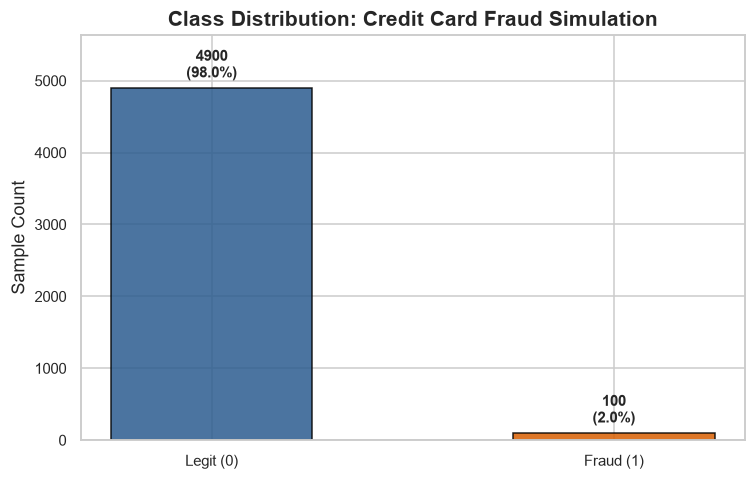

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
counts = [n_maj, n_min]
bars = ax.bar(['Legit (0)', 'Fraud (1)'], counts, color=[COLORS['majority'], COLORS['minority']],
              width=0.5, edgecolor='black', alpha=0.85)
ax.set_ylim(0, max(counts) * 1.15)
ax.set_ylabel('Sample Count')
for bar in bars:
    h = bar.get_height()
    ax.annotate(f'{h}\n({h / n_total * 100:.1f}%)', xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_title('Class Distribution: Credit Card Fraud Simulation', fontweight='bold')
plt.show()

> **Key Takeaway:** Only 100 of 5,000 transactions are fraud (49:1). An unweighted classifier can reach 98% accuracy by never predicting fraud, so the minority class has to be rebalanced, and rebalanced well.

## 2. Data Quality Audit and Cleaning
Each check below protects a step of SMOTE: `NaN` and `±∞` break distance computations, duplicate fraud rows get
oversampled twice, constant columns divide by zero during scaling, and non-numeric columns cannot be interpolated.

In [4]:
num = df[FEATURES]
df_quality = pd.DataFrame([
    {'Check': 'Missing cells', 'Count': int(num.isna().sum().sum()), 'Rule if found': 'Median-impute (fit on train fold)'},
    {'Check': 'Infinite cells', 'Count': int(np.isinf(num.values).sum()), 'Rule if found': 'Convert to NaN, then impute'},
    {'Check': 'Duplicate rows', 'Count': int(df.duplicated().sum()), 'Rule if found': 'Drop duplicates'},
    {'Check': 'Constant columns', 'Count': int((num.nunique() <= 1).sum()), 'Rule if found': 'Drop column'},
    {'Check': 'Non-numeric columns', 'Count': int((~num.dtypes.apply(pd.api.types.is_numeric_dtype)).sum()), 'Rule if found': 'One-hot encode'},
])
df_quality['Status'] = np.where(df_quality['Count'] == 0, 'Clean', 'Fix applied')
display(df_quality)

df_clean = df.replace([np.inf, -np.inf], np.nan).drop_duplicates()
df_clean = df_clean.loc[:, (df_clean.nunique() > 1) | (df_clean.columns == 'target')]
display(pd.DataFrame({'Rows': [len(df), len(df_clean)], 'Columns': [df.shape[1], df_clean.shape[1]]},
                     index=['Before cleaning', 'After cleaning']))

,Check,Count,Rule if found,Status
0,Missing cells,0,Median-impute (fit on train fold),Clean
1,Infinite cells,0,"Convert to NaN, then impute",Clean
2,Duplicate rows,0,Drop duplicates,Clean
3,Constant columns,0,Drop column,Clean
4,Non-numeric columns,0,One-hot encode,Clean


,Rows,Columns
Before cleaning,5000,29
After cleaning,5000,29


> **Key Takeaway:** The simulation passes every quality check, so cleaning removes 0 rows and 0 columns. The cleaning step is kept anyway, so the same notebook works on the real Kaggle card-fraud file.

## 3. Outlier Analysis: Why Outliers Are Flagged, Not Removed
A row is flagged as an outlier when any component has $|z| > 3$.

In [5]:
z = (num - num.mean()) / num.std()
is_outlier = (z.abs() > 3).any(axis=1)
df_outliers = pd.crosstab(is_outlier.rename('Row has |z| > 3'), df['target'].map({0: 'Legit', 1: 'Fraud'}))
df_outliers['Fraud Share'] = (df_outliers['Fraud'] / df_outliers.sum(axis=1)).map('{:.1%}'.format)
display(df_outliers)
print(f"Removing outlier rows would delete {df_outliers.loc[True, 'Fraud'] / n_min:.0%} of all fraud "
      f"but only {df_outliers.loc[True, 'Legit'] / n_maj:.0%} of legit transactions.")

target,Fraud,Legit,Fraud Share
Row has |z| > 3,,,
False,0,4593,0.0%
True,100,307,24.6%


Removing outlier rows would delete 100% of all fraud but only 6% of legit transactions.


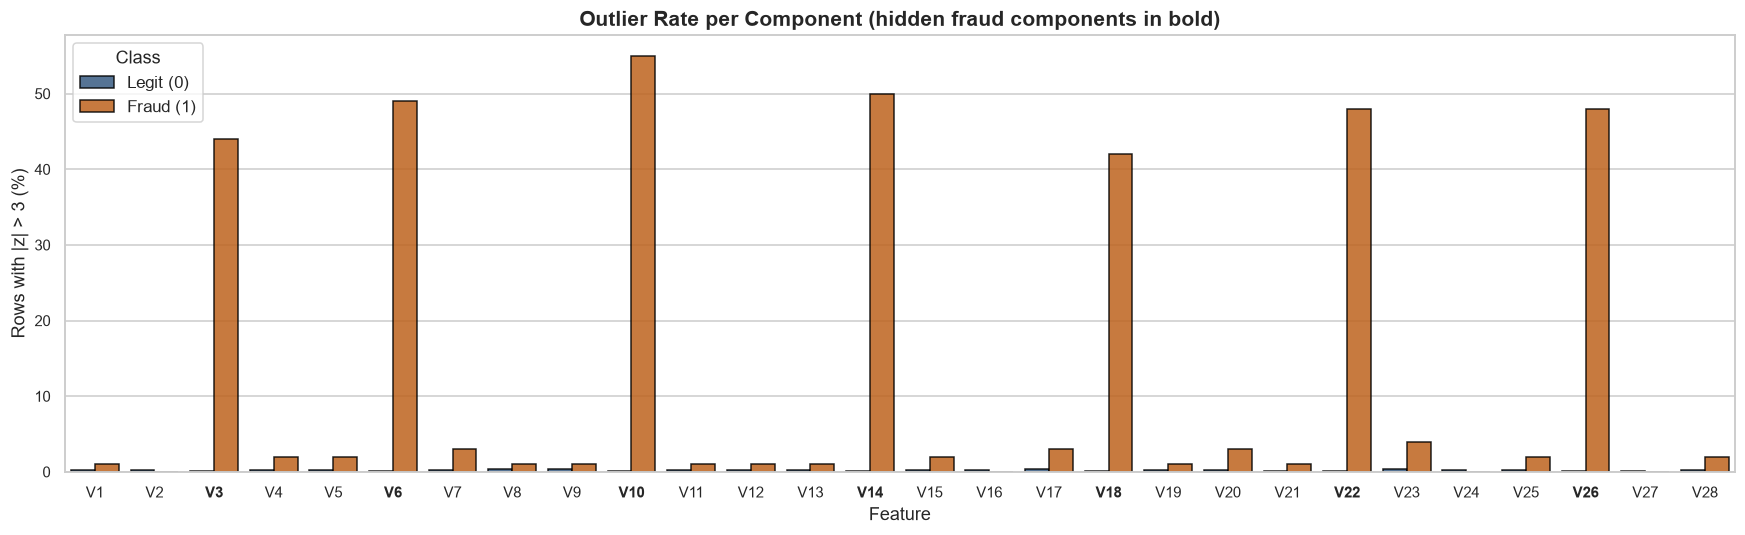

In [6]:
out_rate = pd.DataFrame({
    'Legit (0)': (z[df['target'] == 0].abs() > 3).mean() * 100,
    'Fraud (1)': (z[df['target'] == 1].abs() > 3).mean() * 100,
}).rename_axis('Feature').reset_index().melt(id_vars='Feature', var_name='Class', value_name='Outlier %')

fig, ax = plt.subplots(figsize=(16, 5))
sns.barplot(data=out_rate, x='Feature', y='Outlier %', hue='Class',
            palette=[COLORS['majority'], COLORS['minority']], edgecolor='black', alpha=0.85, ax=ax)
for lbl in ax.get_xticklabels():
    if lbl.get_text() in TRUE_FRAUD:
        lbl.set_fontweight('bold')
ax.set_ylabel('Rows with |z| > 3 (%)')
ax.set_title('Outlier Rate per Component (hidden fraud components in bold)', fontweight='bold')
plt.show()

> **Key Takeaway:** Every fraud row is a statistical outlier, and the outliers sit almost entirely on the hidden fraud components. In fraud detection the outliers are the signal, so the pipeline never deletes them.

## 4. Feature Separability: Two-Sample Kolmogorov-Smirnov Tests
We compute the KS $D$-statistic between the legit and fraud distributions of every component.

In [7]:
ks_records = []
for f in FEATURES:
    d_stat, p_val = ks_2samp(df.loc[df.target == 0, f], df.loc[df.target == 1, f])
    ks_records.append({'Feature': f, 'KS_D_Statistic': d_stat, 'P_Value': p_val, 'Hidden_Fraud': f in TRUE_FRAUD})
df_ks = pd.DataFrame(ks_records).sort_values('KS_D_Statistic', ascending=False).reset_index(drop=True)
display(df_ks.head(10))

,Feature,KS_D_Statistic,P_Value,Hidden_Fraud
0,V26,0.475306,7.954632e-21,True
1,V3,0.471224,1.858138e-20,True
2,V6,0.444694,3.699669e-18,True
3,V22,0.440204,8.731852e-18,True
4,V18,0.425306,1.399377e-16,True
5,V14,0.423673,1.883432e-16,True
6,V10,0.417755,5.466175e-16,True
7,V24,0.209796,2.933894e-04,False
8,V13,0.166939,7.463986e-03,False
9,V7,0.137551,4.457724e-02,False


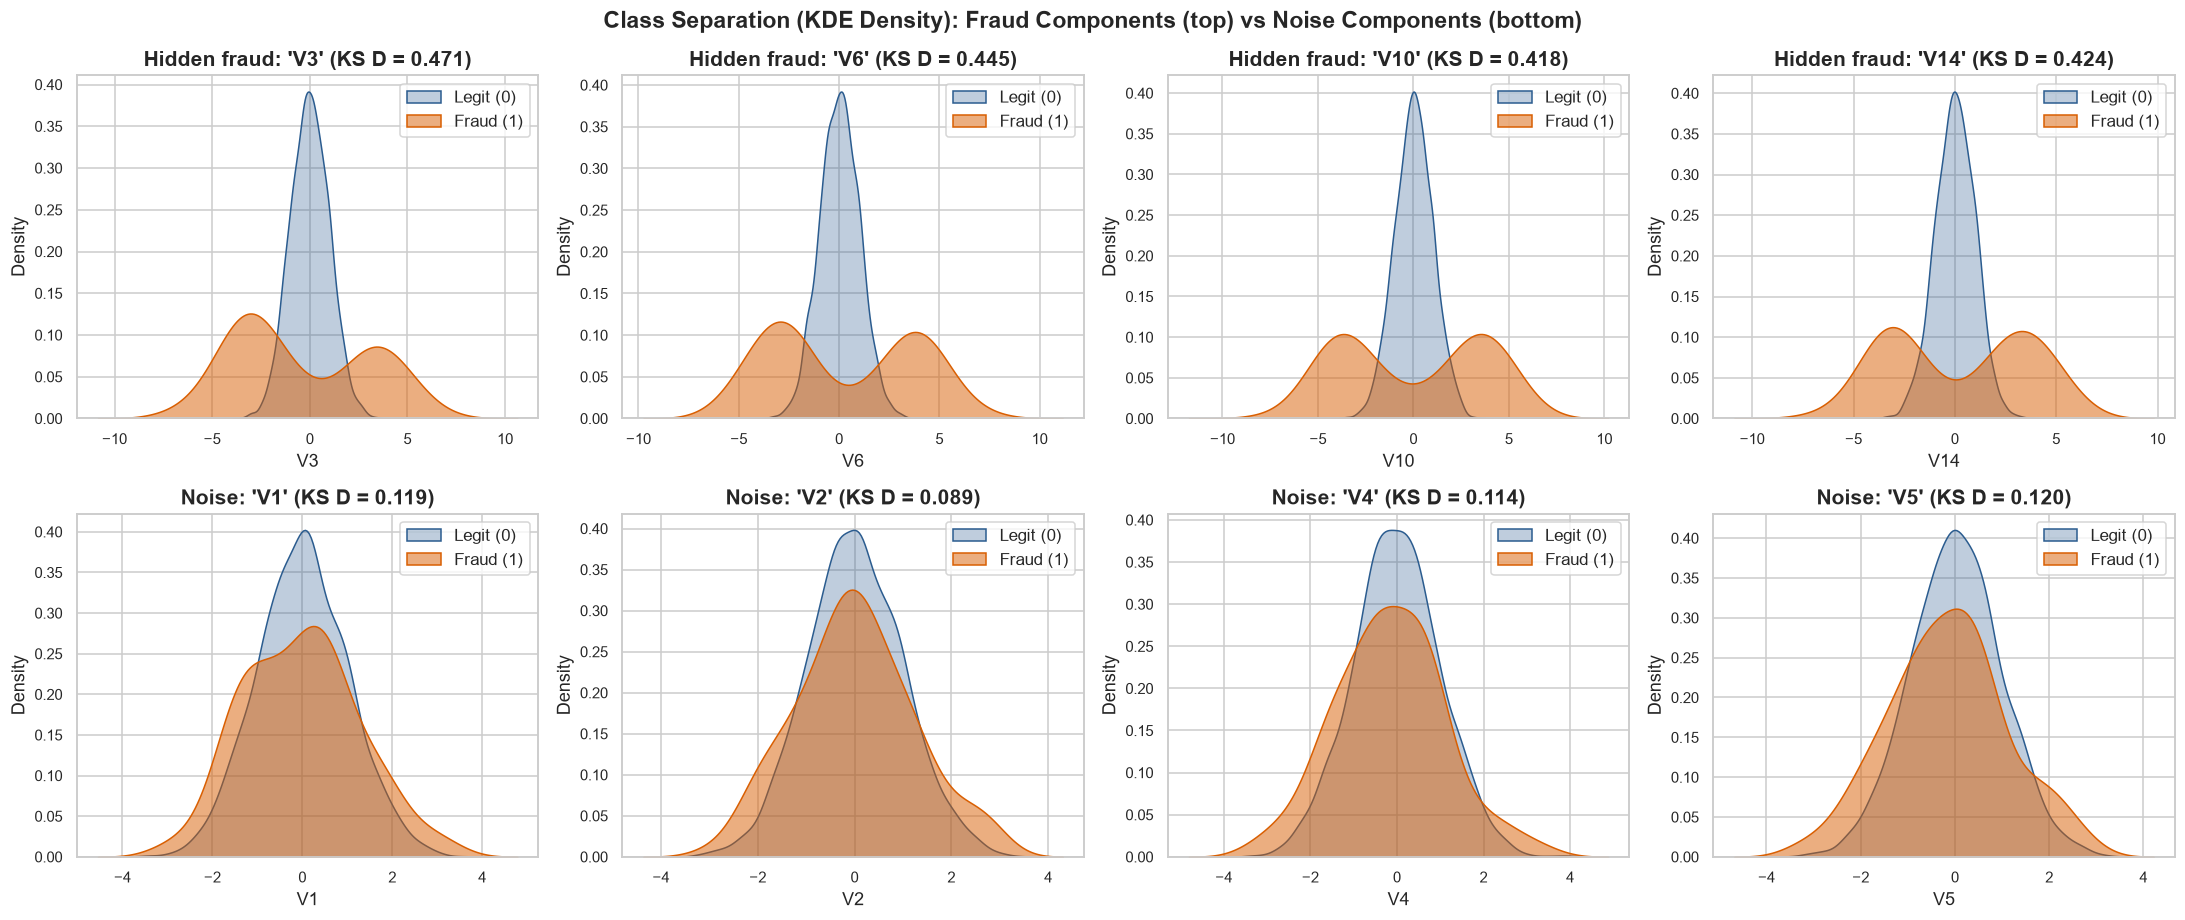

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8.5))
for ax, f in zip(axes.flatten(), TRUE_FRAUD[:4] + NOISE[:4]):
    d_val = df_ks.loc[df_ks.Feature == f, 'KS_D_Statistic'].values[0]
    sns.kdeplot(data=df[df.target == 0], x=f, label='Legit (0)', color=COLORS['majority'], fill=True, alpha=0.3, ax=ax)
    sns.kdeplot(data=df[df.target == 1], x=f, label='Fraud (1)', color=COLORS['minority'], fill=True, alpha=0.5, ax=ax)
    kind = 'Hidden fraud' if f in TRUE_FRAUD else 'Noise'
    ax.set_title(f"{kind}: '{f}' (KS D = {d_val:.3f})", fontweight='bold')
    ax.set_ylabel('Density')
    ax.legend()
plt.suptitle('Class Separation (KDE Density): Fraud Components (top) vs Noise Components (bottom)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

> **Key Takeaway:** Fraud is **bimodal** on the signal components, with one cluster near +3σ and another near −3σ, while the noise components overlap completely. Plain SMOTE that interpolates between a "+3σ" fraud and a "−3σ" fraud lands in the middle of the legit cloud, which is the failure SHAP guidance targets.

## 5. Leak-Free Train/Test Split and Feature Scaling
Everything that *learns* from the data (the scaler, the SHAP model, and the oversampler) is fit on the **training fold only**.
The test fold is only transformed and keeps its natural 2% fraud rate.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    df_clean[FEATURES].values, df_clean['target'].values,
    test_size=0.25, stratify=df_clean['target'].values, random_state=SEED,
)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

df_split = pd.DataFrame({
    'Samples': [len(y_train), len(y_test)],
    'Majority (0)': [int((y_train == 0).sum()), int((y_test == 0).sum())],
    'Minority (1)': [int((y_train == 1).sum()), int((y_test == 1).sum())],
}, index=['Train fold', 'Test fold'])
df_split['Minority %'] = (df_split['Minority (1)'] / df_split['Samples'] * 100).map('{:.2f}%'.format)
display(df_split)

df_scaling = pd.DataFrame({
    'Train Mean (before)': X_train.mean(0), 'Train Std (before)': X_train.std(0),
    'Train Mean (after)': X_train_s.mean(0), 'Train Std (after)': X_train_s.std(0),
    'Test Mean (after)': X_test_s.mean(0), 'Test Std (after)': X_test_s.std(0),
}, index=FEATURES).loc[TRUE_FRAUD[:3] + NOISE[:3]].round(3)
display(df_scaling)

,Samples,Majority (0),Minority (1),Minority %
Train fold,3750,3675,75,2.00%
Test fold,1250,1225,25,2.00%


,Train Mean (before),Train Std (before),Train Mean (after),Train Std (after),Test Mean (after),Test Std (after)
V3,-0.015,1.114,-0.0,1.0,-0.031,0.975
V6,0.013,1.121,0.0,1.0,0.014,0.974
V10,-0.009,1.130,-0.0,1.0,0.068,0.987
V1,0.011,1.025,0.0,1.0,-0.034,0.999
V2,0.024,1.005,0.0,1.0,-0.044,0.999
V4,-0.030,1.016,-0.0,1.0,0.070,1.010


> **Key Takeaway:** After scaling, the training fold is exactly mean 0 / std 1, while the test fold is only close to it, because the scaler never saw the test data. That small mismatch shows there is no leakage.

## 6. SHAP Attribution: Mean Absolute SHAP Value (MASV) Feature Weights
`compute_masv_weights` fits a preliminary Random Forest (50 trees, depth 5) on the scaled training fold, explains it with
`shap.TreeExplainer`, and normalises the per-feature importance:

$$\text{MASV}_j = \frac{1}{N}\sum_{i=1}^{N} |\phi_j(x_i)|, \qquad w_j = \frac{\text{MASV}_j}{\sum_k \text{MASV}_k}$$

In [10]:
weights, masv, prelim_rf = compute_masv_weights(X_train_s, y_train, random_state=SEED)

df_masv = pd.DataFrame({'Feature': FEATURES, 'MASV': masv, 'Weight_w': weights, 'Hidden_Fraud': [f in TRUE_FRAUD for f in FEATURES]})
df_masv = df_masv.sort_values('MASV', ascending=False).reset_index(drop=True)
df_masv['Cumulative_Weight'] = df_masv['Weight_w'].cumsum()
display(df_masv.head(10))

top_shap = df_masv['Feature'].head(len(TRUE_FRAUD)).tolist()
print(f'SHAP top-{len(TRUE_FRAUD)}: {top_shap}')
print(f'Hidden fraud components recovered: {len(set(top_shap) & set(TRUE_FRAUD))}/{len(TRUE_FRAUD)} | '
      f'share of SHAP weight: {df_masv.loc[df_masv.Hidden_Fraud, "Weight_w"].sum():.1%} '
      f'(uniform weighting would give {len(TRUE_FRAUD) / len(FEATURES):.1%})')

,Feature,MASV,Weight_w,Hidden_Fraud,Cumulative_Weight
0,V10,0.007010,0.190921,True,0.190921
1,V6,0.006008,0.163635,True,0.354556
2,V26,0.004992,0.135953,True,0.490510
3,V3,0.004370,0.119010,True,0.609520
4,V14,0.004192,0.114179,True,0.723699
5,V18,0.003785,0.103093,True,0.826792
6,V22,0.002837,0.077276,True,0.904068
7,V20,0.000337,0.009175,False,0.913243
8,V21,0.000313,0.008519,False,0.921762
9,V17,0.000312,0.008488,False,0.930250


SHAP top-7: ['V10', 'V6', 'V26', 'V3', 'V14', 'V18', 'V22']
Hidden fraud components recovered: 7/7 | share of SHAP weight: 90.4% (uniform weighting would give 25.0%)


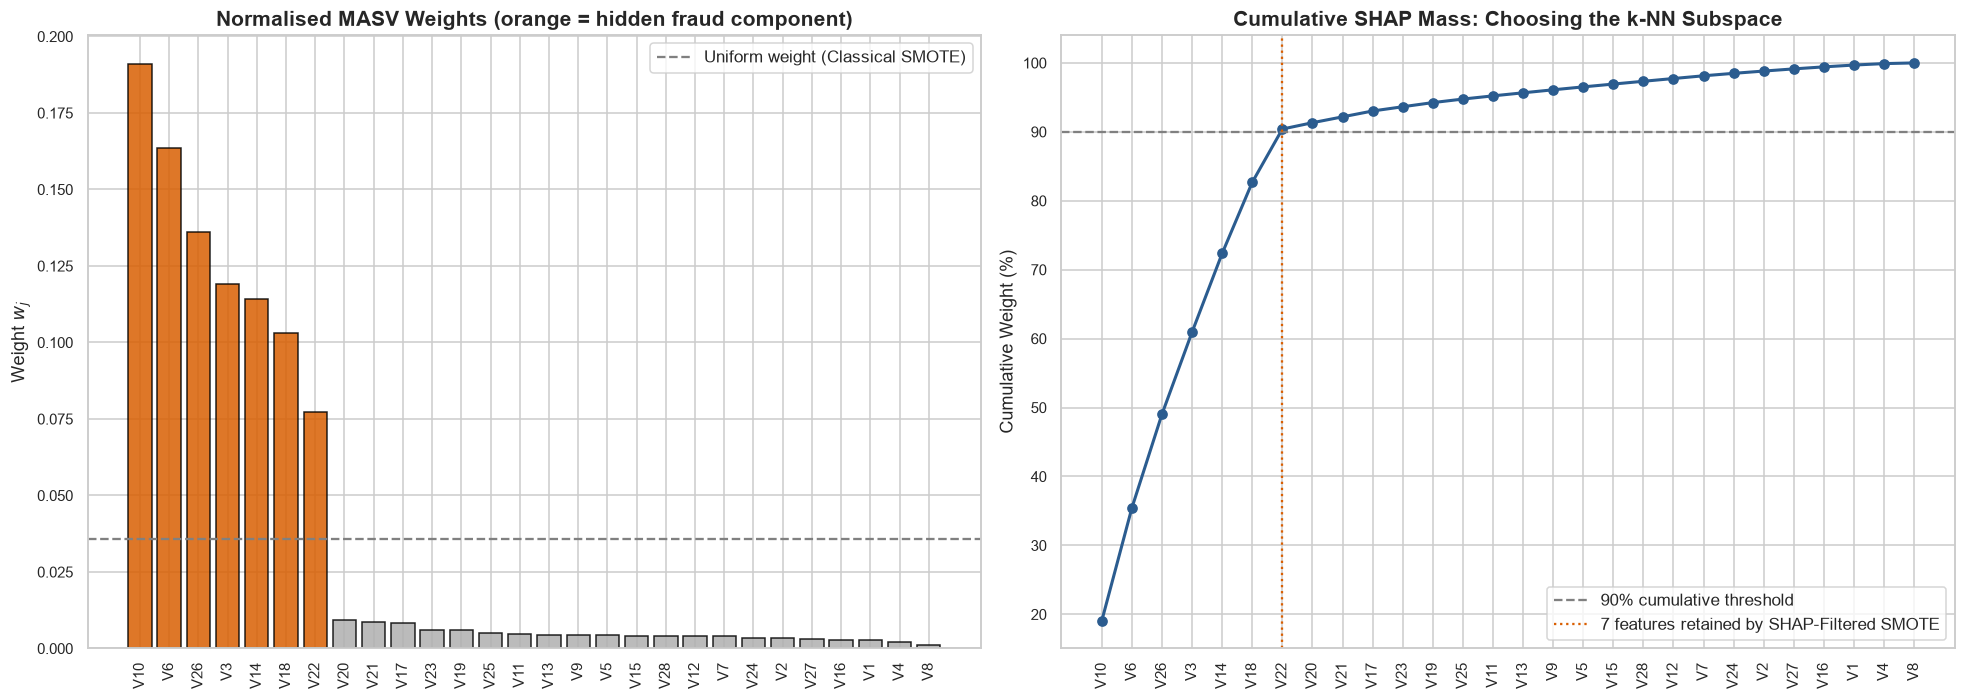

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

bar_colors = [COLORS['minority'] if h else COLORS['noise'] for h in df_masv['Hidden_Fraud']]
axes[0].bar(df_masv['Feature'], df_masv['Weight_w'], color=bar_colors, edgecolor='black', alpha=0.85)
axes[0].axhline(1 / len(FEATURES), color='gray', linestyle='--', label='Uniform weight (Classical SMOTE)')
axes[0].set_title('Normalised MASV Weights (orange = hidden fraud component)', fontweight='bold')
axes[0].set_ylabel('Weight $w_j$')
axes[0].tick_params(axis='x', rotation=90)
axes[0].legend()

k90 = int(np.searchsorted(df_masv['Cumulative_Weight'].values, 0.90) + 1)
axes[1].plot(df_masv['Feature'], df_masv['Cumulative_Weight'] * 100, marker='o', color=COLORS['majority'], linewidth=2)
axes[1].axhline(90, color='gray', linestyle='--', label='90% cumulative threshold')
axes[1].axvline(k90 - 1, color=COLORS['minority'], linestyle=':', label=f'{k90} features retained by SHAP-Filtered SMOTE')
axes[1].set_title('Cumulative SHAP Mass: Choosing the k-NN Subspace', fontweight='bold')
axes[1].set_ylabel('Cumulative Weight (%)')
axes[1].tick_params(axis='x', rotation=90)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

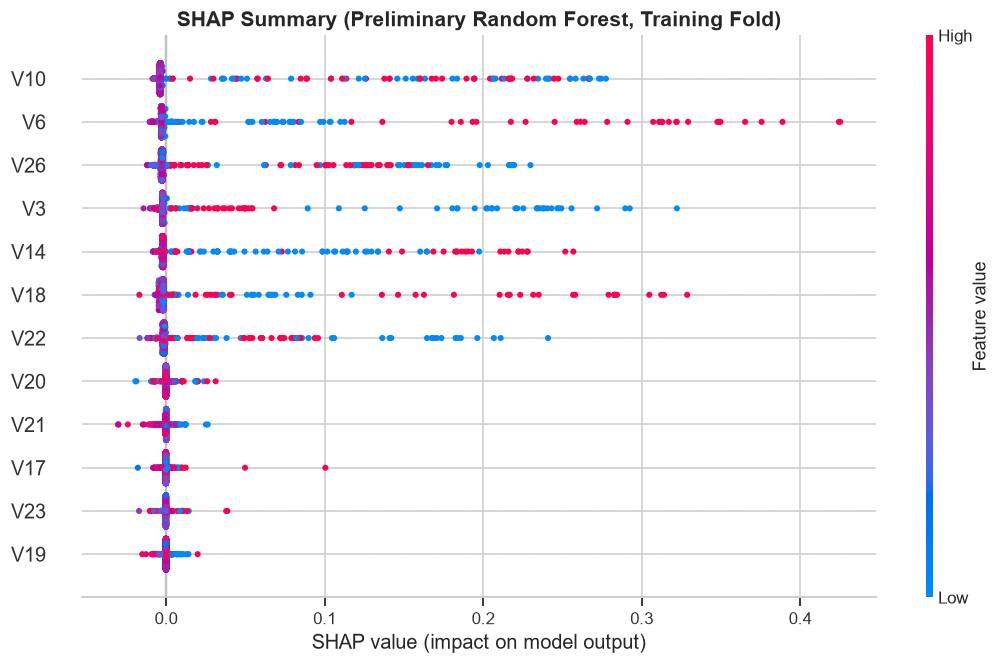

In [12]:
sv = shap.TreeExplainer(prelim_rf).shap_values(X_train_s)
sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)
shap.summary_plot(sv, X_train_s, feature_names=FEATURES, max_display=12, show=False, plot_size=(10, 6))
plt.title('SHAP Summary (Preliminary Random Forest, Training Fold)', fontweight='bold')
plt.show()

> **Key Takeaway:** With no access to the ground truth, SHAP ranks all **7 hidden fraud components** at the top, and they hold about 90% of the attribution mass. The beeswarm shows both very high and very low values pushing toward fraud, which matches the bimodal pattern from Section 4. Because MASV uses the magnitude $|\phi|$, it captures both sides.

## 7. SHAP-Guided Oversampling: Filtered vs Weighted vs Classical SMOTE
All three methods create $x_{new} = x_a + \lambda (x_{nn} - x_a)$, $\lambda \sim U(0,1)$, in the original feature space.
They differ only in **how the neighbour $x_{nn}$ is chosen**:

| Method | Neighbour Search Space |
|---|---|
| **Classical SMOTE** | All 28 components, equal weight (Euclidean) |
| **SHAP-Filtered SMOTE** | Only the top components holding 90% of the MASV mass |
| **SHAP-Weighted SMOTE** | All 28 components, each scaled by $\sqrt{w_j}$: $d_W = \sqrt{\sum_j w_j (x_{aj}-x_{bj})^2}$ |

In [13]:
samplers = {
    'Raw (no balancing)': RawNoBalancing(),
    'Classical SMOTE': ClassicalSMOTE(k_neighbors=5, random_state=SEED),
    'SHAP-Filtered SMOTE': SHAPFilteredSMOTE(cumulative_threshold=0.90, k_neighbors=5, random_state=SEED),
    'SHAP-Weighted SMOTE': SHAPWeightedSMOTE(k_neighbors=5, random_state=SEED),
}
resampled = {name: s.fit_resample(X_train_s, y_train) for name, s in samplers.items()}
n_train = len(y_train)
# Every sampler appends its synthetic rows after the original rows
synthetic = {name: resampled[name][0][n_train:] for name in OVERSAMPLERS}

filt, wtd = samplers['SHAP-Filtered SMOTE'], samplers['SHAP-Weighted SMOTE']
selected = [FEATURES[i] for i in filt.selected_feature_indices_]
stretch = pd.Series(np.sqrt(weights) / np.sqrt(1 / len(FEATURES)), index=FEATURES)

df_counts = pd.DataFrame([{
    'Method': m,
    'Train Samples': len(yr),
    'Majority (0)': int((yr == 0).sum()),
    'Minority (1)': int((yr == 1).sum()),
    'Synthetic Created': len(yr) - n_train,
    'k-NN Features': {'Raw (no balancing)': '-', 'Classical SMOTE': '28 (equal weight)',
                      'SHAP-Filtered SMOTE': f'{len(selected)} (SHAP subspace)',
                      'SHAP-Weighted SMOTE': '28 (SHAP-weighted)'}[m],
} for m, (Xr, yr) in resampled.items()])
display(df_counts)

print(f'SHAP-Filtered subspace: {selected} | hidden fraud inside: {len(set(selected) & set(TRUE_FRAUD))}/{len(TRUE_FRAUD)}')
print(f'SHAP-Weighted axis stretch vs Classical SMOTE: fraud components x{stretch[TRUE_FRAUD].mean():.2f} on average, '
      f'noise components x{stretch[NOISE].mean():.2f}')

,Method,Train Samples,Majority (0),Minority (1),Synthetic Created,k-NN Features
0,Raw (no balancing),3750,3675,75,0,-
1,Classical SMOTE,7350,3675,3675,3600,28 (equal weight)
2,SHAP-Filtered SMOTE,7350,3675,3675,3600,7 (SHAP subspace)
3,SHAP-Weighted SMOTE,7350,3675,3675,3600,28 (SHAP-weighted)


SHAP-Filtered subspace: ['V10', 'V6', 'V26', 'V3', 'V14', 'V18', 'V22'] | hidden fraud inside: 7/7
SHAP-Weighted axis stretch vs Classical SMOTE: fraud components x1.88 on average, noise components x0.35


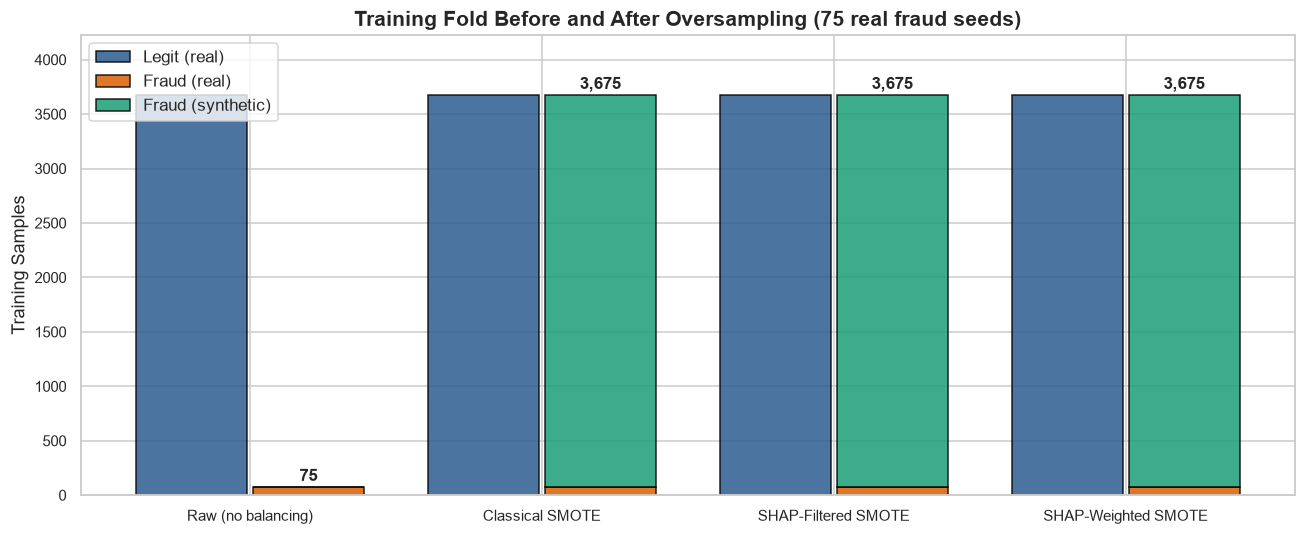

In [14]:
fig, ax = plt.subplots(figsize=(12, 5))
xpos = np.arange(len(METHODS))
real_min = int((y_train == 1).sum())
ax.bar(xpos - 0.2, df_counts['Majority (0)'], width=0.38, color=COLORS['majority'], edgecolor='black', alpha=0.85, label='Legit (real)')
ax.bar(xpos + 0.2, [real_min] * len(METHODS), width=0.38, color=COLORS['minority'], edgecolor='black', alpha=0.85, label='Fraud (real)')
ax.bar(xpos + 0.2, df_counts['Synthetic Created'], bottom=real_min, width=0.38, color=COLORS['synthetic'],
       edgecolor='black', alpha=0.85, label='Fraud (synthetic)')
for i, v in enumerate(df_counts['Minority (1)']):
    ax.annotate(f'{v:,}', xy=(i + 0.2, v), xytext=(0, 4), textcoords='offset points', ha='center', fontweight='bold')
ax.set_xticks(xpos, METHODS)
ax.set_ylabel('Training Samples')
ax.set_ylim(0, df_counts['Majority (0)'].max() * 1.15)
ax.set_title(f'Training Fold Before and After Oversampling ({real_min} real fraud seeds)', fontweight='bold')
ax.legend(loc='upper left')
plt.show()

> **Key Takeaway:** Every oversampler turns the 75 real training frauds into 3,675 (1:1 balance). SHAP-Filtered SMOTE searches neighbours in exactly the 7 hidden fraud components. SHAP-Weighted SMOTE stretches those components by about 2× and shrinks the noise components to about 0.35×.

## 8. Neighbour Graph Quality
For every training fraud we take its 5 nearest fraud neighbours in each search space and measure:
- **Gap on Fraud Components**: mean $|x_a - x_{nn}|$ on the 7 signal components (lower is better)
- **Sign Agreement**: the share of signal components where the pair sits on the same side, ±3σ (higher is better)

,Method,Gap on Fraud Components,Gap on Noise Components,Sign Agreement (%)
0,Classical SMOTE,1.991,1.293,79.010
1,SHAP-Filtered SMOTE,1.910,1.392,80.533
2,SHAP-Weighted SMOTE,1.957,1.391,79.771


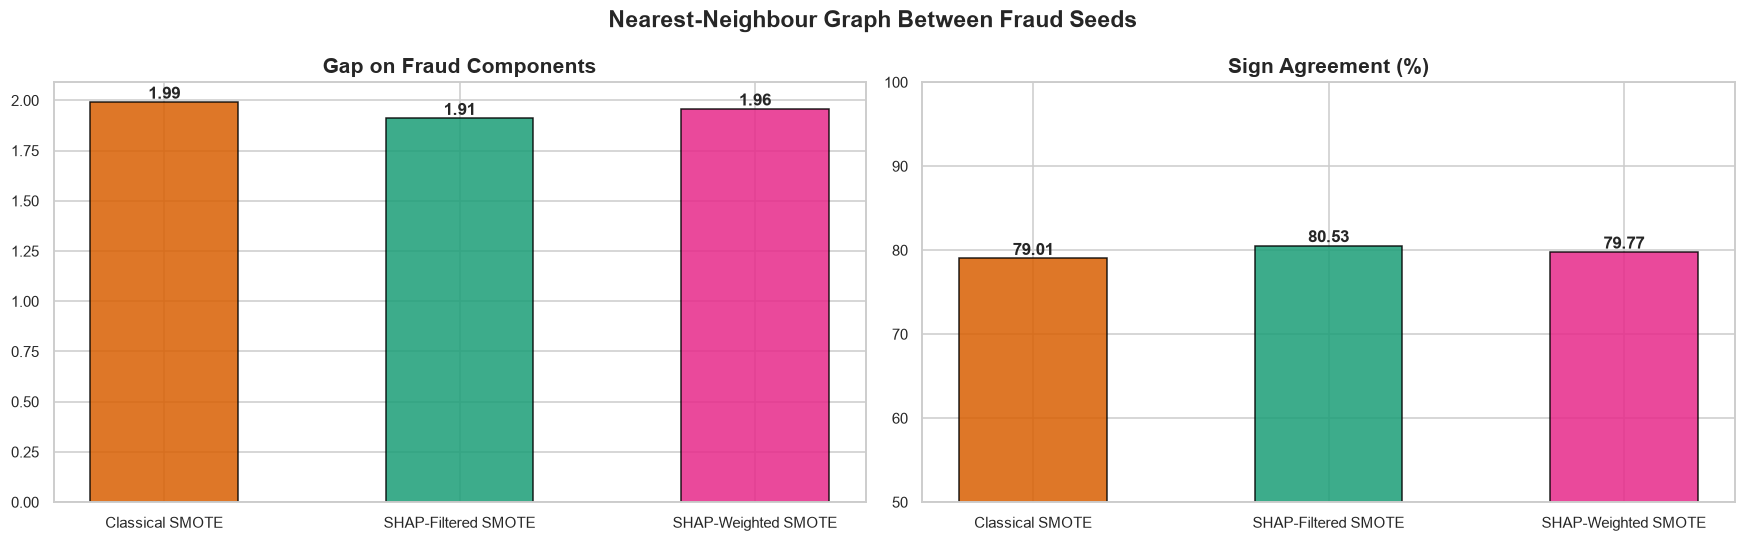

In [15]:
X_fraud = X_train_s[y_train == 1]
spaces = {
    'Classical SMOTE': X_fraud,
    'SHAP-Filtered SMOTE': X_fraud[:, filt.selected_feature_indices_],
    'SHAP-Weighted SMOTE': X_fraud * np.sqrt(weights),
}
sig = np.array(TRUE_FRAUD_IDX)
noi = np.array([FEATURES.index(f) for f in NOISE])

neigh_records = []
for name, Z in spaces.items():
    nn_idx = NearestNeighbors(n_neighbors=6).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
    diff = np.abs(X_fraud[:, None, :] - X_fraud[nn_idx])
    same_side = np.sign(X_fraud[:, None, sig]) == np.sign(X_fraud[nn_idx][:, :, sig])
    neigh_records.append({'Method': name,
                          'Gap on Fraud Components': diff[:, :, sig].mean(),
                          'Gap on Noise Components': diff[:, :, noi].mean(),
                          'Sign Agreement (%)': same_side.mean() * 100})
df_neigh = pd.DataFrame(neigh_records).round(3)
display(df_neigh)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col, ylim in [(axes[0], 'Gap on Fraud Components', None), (axes[1], 'Sign Agreement (%)', (50, 100))]:
    ax.bar(df_neigh['Method'], df_neigh[col], color=[METHOD_COLORS[m] for m in df_neigh['Method']],
           edgecolor='black', alpha=0.85, width=0.5)
    for i, v in enumerate(df_neigh[col]):
        ax.text(i, v, f'{v:.2f}', ha='center', va='bottom', fontweight='bold')
    ax.set_title(col, fontweight='bold')
    if ylim:
        ax.set_ylim(*ylim)
plt.suptitle('Nearest-Neighbour Graph Between Fraud Seeds', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

> **Key Takeaway:** SHAP guidance shifts the neighbour graph in the right direction (sign agreement 79.0% → 80.5%, a smaller gap on the fraud components), but only slightly. In this simulation the ±3σ fraud shifts already dominate plain Euclidean distance, so Classical SMOTE already picks mostly sensible neighbours.

## 9. Synthetic Sample Placement
Where do the 3,600 synthetic frauds land? Synthetic points in the legit centre come from neighbour pairs that sit on
opposite sides of a fraud component.

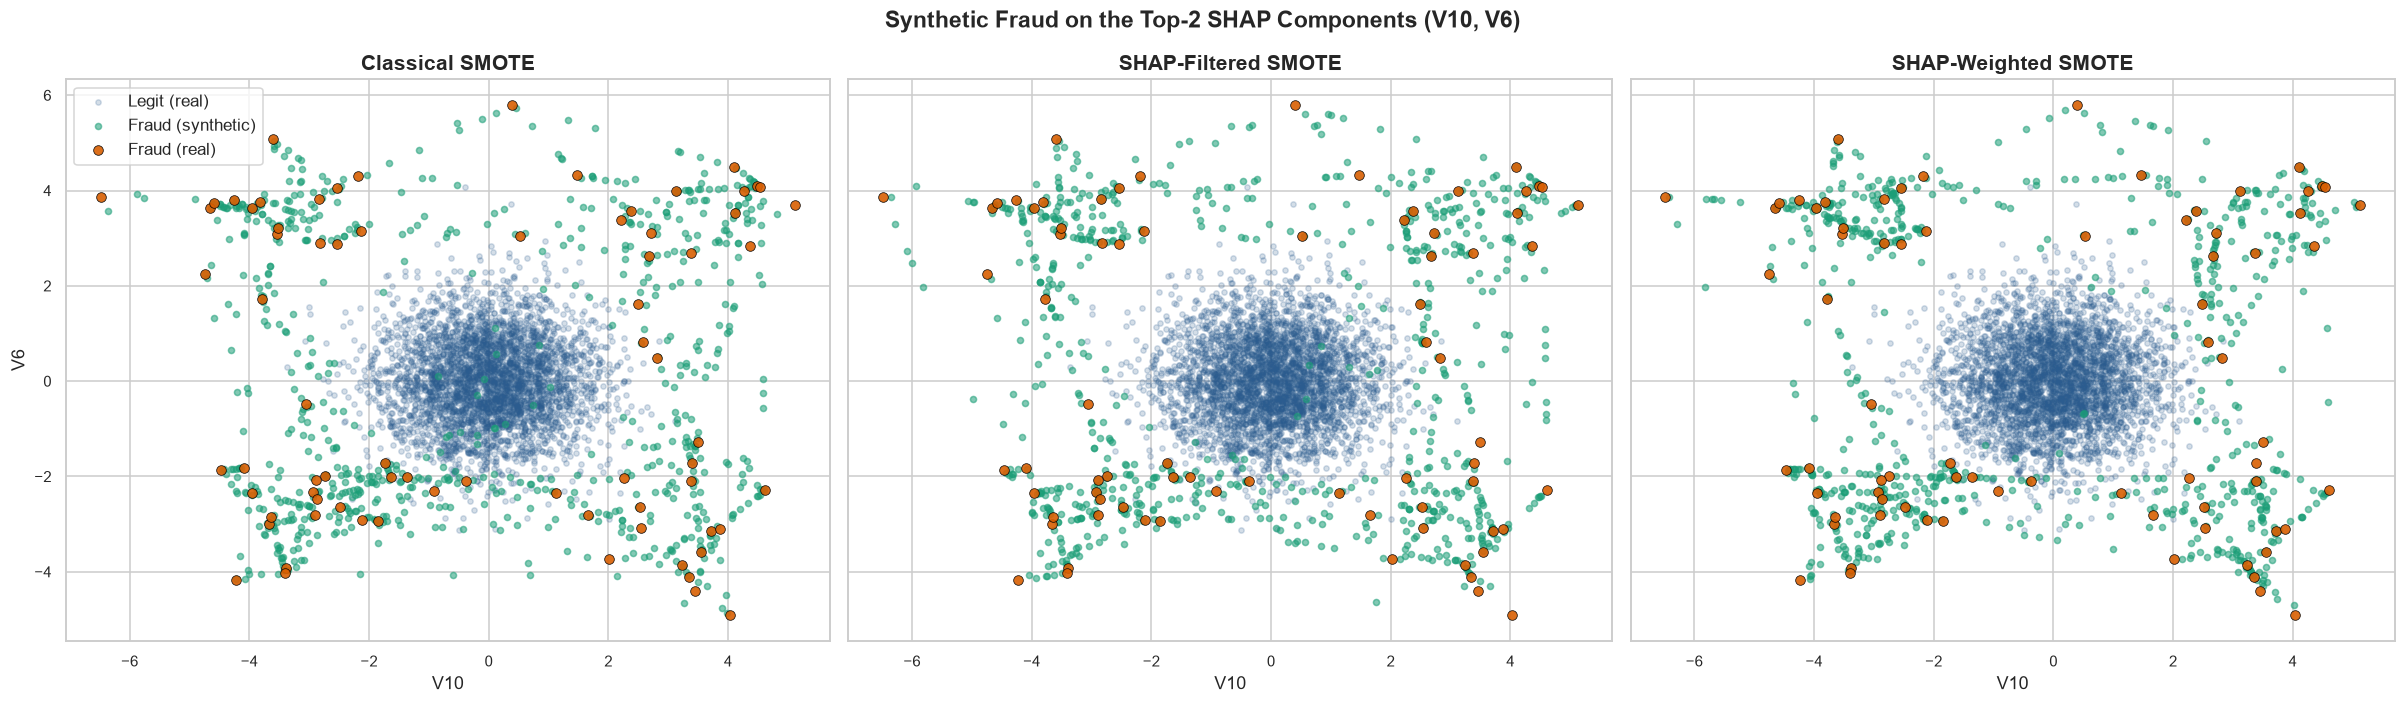

In [16]:
fa, fb = FEATURES.index(top_shap[0]), FEATURES.index(top_shap[1])
rng = np.random.default_rng(SEED)
X_legit = X_train_s[y_train == 0]

fig, axes = plt.subplots(1, 3, figsize=(22, 6.5), sharex=True, sharey=True)
for ax, name in zip(axes, OVERSAMPLERS):
    S = synthetic[name][rng.choice(len(synthetic[name]), 800, replace=False)]
    ax.scatter(X_legit[:, fa], X_legit[:, fb], c=COLORS['majority'], label='Legit (real)', alpha=0.2, s=12)
    ax.scatter(S[:, fa], S[:, fb], c=COLORS['synthetic'], label='Fraud (synthetic)', alpha=0.55, s=16)
    ax.scatter(X_fraud[:, fa], X_fraud[:, fb], c=COLORS['minority'], label='Fraud (real)', alpha=0.9, s=40,
               edgecolors='black', linewidth=0.5)
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel(FEATURES[fa])
axes[0].set_ylabel(FEATURES[fb])
axes[0].legend()
plt.suptitle(f'Synthetic Fraud on the Top-2 SHAP Components ({FEATURES[fa]}, {FEATURES[fb]})', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

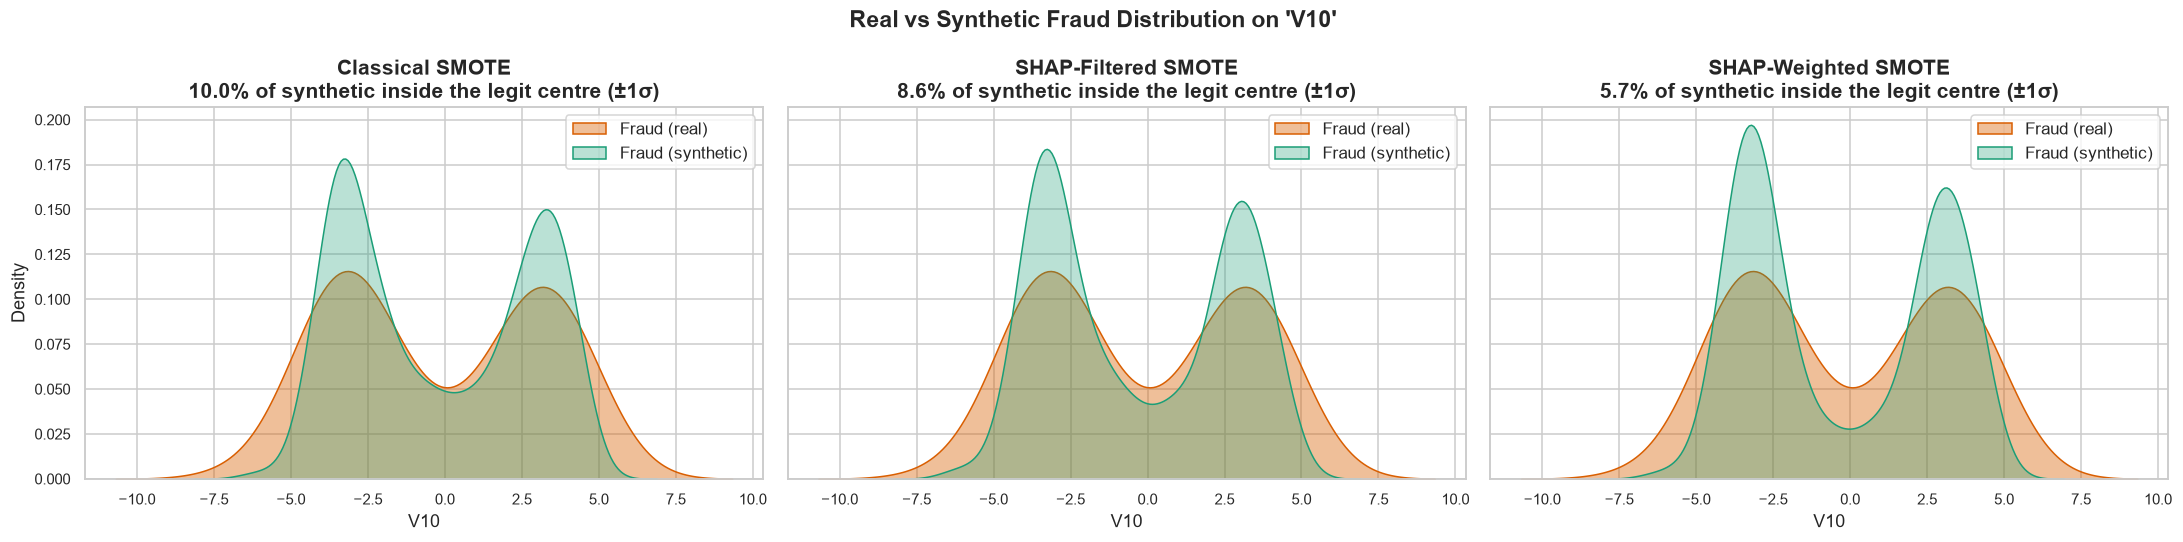

In [17]:
j = FEATURES.index(top_shap[0])
fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for ax, name in zip(axes, OVERSAMPLERS):
    sns.kdeplot(X_fraud[:, j], label='Fraud (real)', color=COLORS['minority'], fill=True, alpha=0.4, ax=ax)
    sns.kdeplot(synthetic[name][:, j], label='Fraud (synthetic)', color=COLORS['synthetic'], fill=True, alpha=0.3, ax=ax)
    centre = (np.abs(synthetic[name][:, j]) < 1).mean() * 100
    ax.set_title(f'{name}\n{centre:.1f}% of synthetic inside the legit centre (±1σ)', fontweight='bold')
    ax.set_xlabel(top_shap[0])
    ax.legend()
plt.suptitle(f"Real vs Synthetic Fraud Distribution on '{top_shap[0]}'", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

> **Key Takeaway:** On the top SHAP component, Classical SMOTE puts about 10% of its synthetic fraud in the legit centre (±1σ). SHAP-Weighted SMOTE puts about 6% there. The SHAP-guided methods follow the two real fraud clusters more closely.

## 10. Synthetic Realism and Statistical Fidelity
**Oracle check:** we draw 40,000 fresh transactions from the same simulator (a different seed, never used in training)
and fit an *oracle* Random Forest on them. A synthetic fraud the oracle scores as legit is **label noise**.
**Fidelity:** `compute_synthetic_fidelity` compares real and synthetic fraud with marginal Wasserstein distances,
KS tests, and covariance/correlation preservation.

In [18]:
X_oracle, y_oracle, _ = load_benchmark_dataset('credit_fraud', random_state=SEED + 1000, n_samples=40000, minority_ratio=0.02)
oracle = RandomForestClassifier(n_estimators=300, class_weight='balanced', n_jobs=-1, random_state=SEED).fit(X_oracle, y_oracle)

realism_records = []
for name in OVERSAMPLERS:
    p_fraud = oracle.predict_proba(scaler.inverse_transform(synthetic[name]))[:, 1]
    realism_records.append({'Method': name, **compute_synthetic_fidelity(X_fraud, synthetic[name]),
                            'Oracle Label Noise (%)': (p_fraud < 0.5).mean() * 100,
                            'Mean Oracle P(fraud)': p_fraud.mean()})
df_fidelity = pd.DataFrame(realism_records).set_index('Method').round(3)
display(df_fidelity)

,mean_wasserstein_distance,max_wasserstein_distance,ks_test_pass_ratio,covariance_frobenius_dist,correlation_matrix_similarity,Oracle Label Noise (%),Mean Oracle P(fraud)
Method,,,,,,,
Classical SMOTE,0.219,0.378,1.0,6.578,0.939,3.194,0.784
SHAP-Filtered SMOTE,0.218,0.345,1.0,6.223,0.944,3.444,0.786
SHAP-Weighted SMOTE,0.229,0.454,1.0,6.793,0.930,2.722,0.787


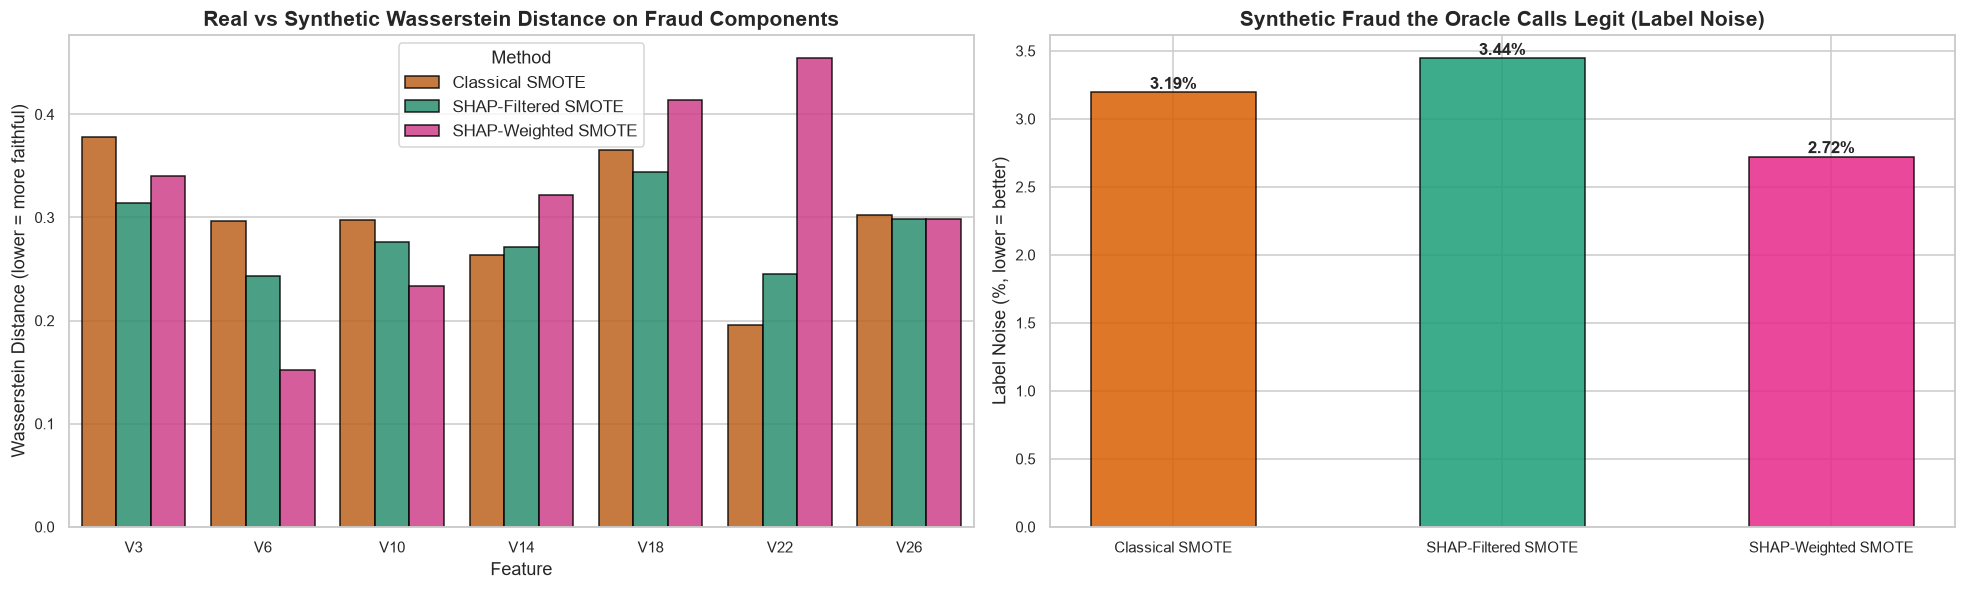

In [19]:
wd = pd.DataFrame({name: [wasserstein_distance(X_fraud[:, j], synthetic[name][:, j]) for j in TRUE_FRAUD_IDX]
                   for name in OVERSAMPLERS}, index=TRUE_FRAUD)
wd_long = wd.rename_axis('Feature').reset_index().melt(id_vars='Feature', var_name='Method', value_name='Wasserstein')

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
sns.barplot(data=wd_long, x='Feature', y='Wasserstein', hue='Method', palette=[METHOD_COLORS[m] for m in OVERSAMPLERS],
            edgecolor='black', alpha=0.85, ax=axes[0])
axes[0].set_title('Real vs Synthetic Wasserstein Distance on Fraud Components', fontweight='bold')
axes[0].set_ylabel('Wasserstein Distance (lower = more faithful)')

noise_pct = df_fidelity['Oracle Label Noise (%)']
axes[1].bar(noise_pct.index, noise_pct.values, color=[METHOD_COLORS[m] for m in noise_pct.index],
            edgecolor='black', alpha=0.85, width=0.5)
for i, v in enumerate(noise_pct.values):
    axes[1].text(i, v, f'{v:.2f}%', ha='center', va='bottom', fontweight='bold')
axes[1].set_title('Synthetic Fraud the Oracle Calls Legit (Label Noise)', fontweight='bold')
axes[1].set_ylabel('Label Noise (%, lower = better)')
plt.tight_layout()
plt.show()

> **Key Takeaway:** All three oversamplers produce statistically faithful fraud (100% of components pass the KS test, correlation similarity ≥ 0.93). SHAP-Weighted SMOTE gives the lowest oracle label noise (2.72% vs 3.19% for Classical SMOTE), but the differences between methods are small.

## 11. Downstream Classification: Hold-out Test Set
Two classifiers are trained on each resampled training fold and scored on the untouched test fold:
- **k-NN (k = 5):** distance-based, so directly sensitive to *where* synthetic points are placed
- **Random Forest (150 trees):** a strong non-linear ensemble

A linear model is not used: fraud sits on *both* sides (±3σ), so no single hyperplane separates it.

In [20]:
CLASSIFIERS = {
    'k-NN (k=5)': lambda: KNeighborsClassifier(n_neighbors=5),
    'Random Forest': lambda: RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=SEED),
}
holdout_records, fitted = [], {}
for m, (Xr, yr) in resampled.items():
    for c, make in CLASSIFIERS.items():
        clf = make().fit(Xr, yr)
        fitted[(m, c)] = clf
        holdout_records.append({'Classifier': c, 'Method': m, **evaluate_multi_dimensional_metrics(clf, X_test_s, y_test)})
df_holdout = pd.DataFrame(holdout_records)
display(df_holdout.set_index(['Classifier', 'Method'])[
    ['pr_auc', 'roc_auc', 'minority_recall', 'minority_precision', 'minority_f1', 'balanced_accuracy', 'ece']].round(3))

,,pr_auc,roc_auc,minority_recall,minority_precision,minority_f1,balanced_accuracy,ece
Classifier,Method,,,,,,,
k-NN (k=5),Raw (no balancing),0.216,0.60,0.00,0.000,0.000,0.50,0.019
Random Forest,Raw (no balancing),1.000,1.00,1.00,1.000,1.000,1.00,0.010
k-NN (k=5),Classical SMOTE,0.882,0.94,0.84,1.000,0.913,0.92,0.004
Random Forest,Classical SMOTE,1.000,1.00,1.00,0.962,0.980,1.00,0.029
k-NN (k=5),SHAP-Filtered SMOTE,0.882,0.94,0.60,1.000,0.750,0.80,0.007
Random Forest,SHAP-Filtered SMOTE,0.998,1.00,0.96,0.960,0.960,0.98,0.028
k-NN (k=5),SHAP-Weighted SMOTE,0.882,0.94,0.68,1.000,0.810,0.84,0.006
Random Forest,SHAP-Weighted SMOTE,1.000,1.00,1.00,0.962,0.980,1.00,0.027


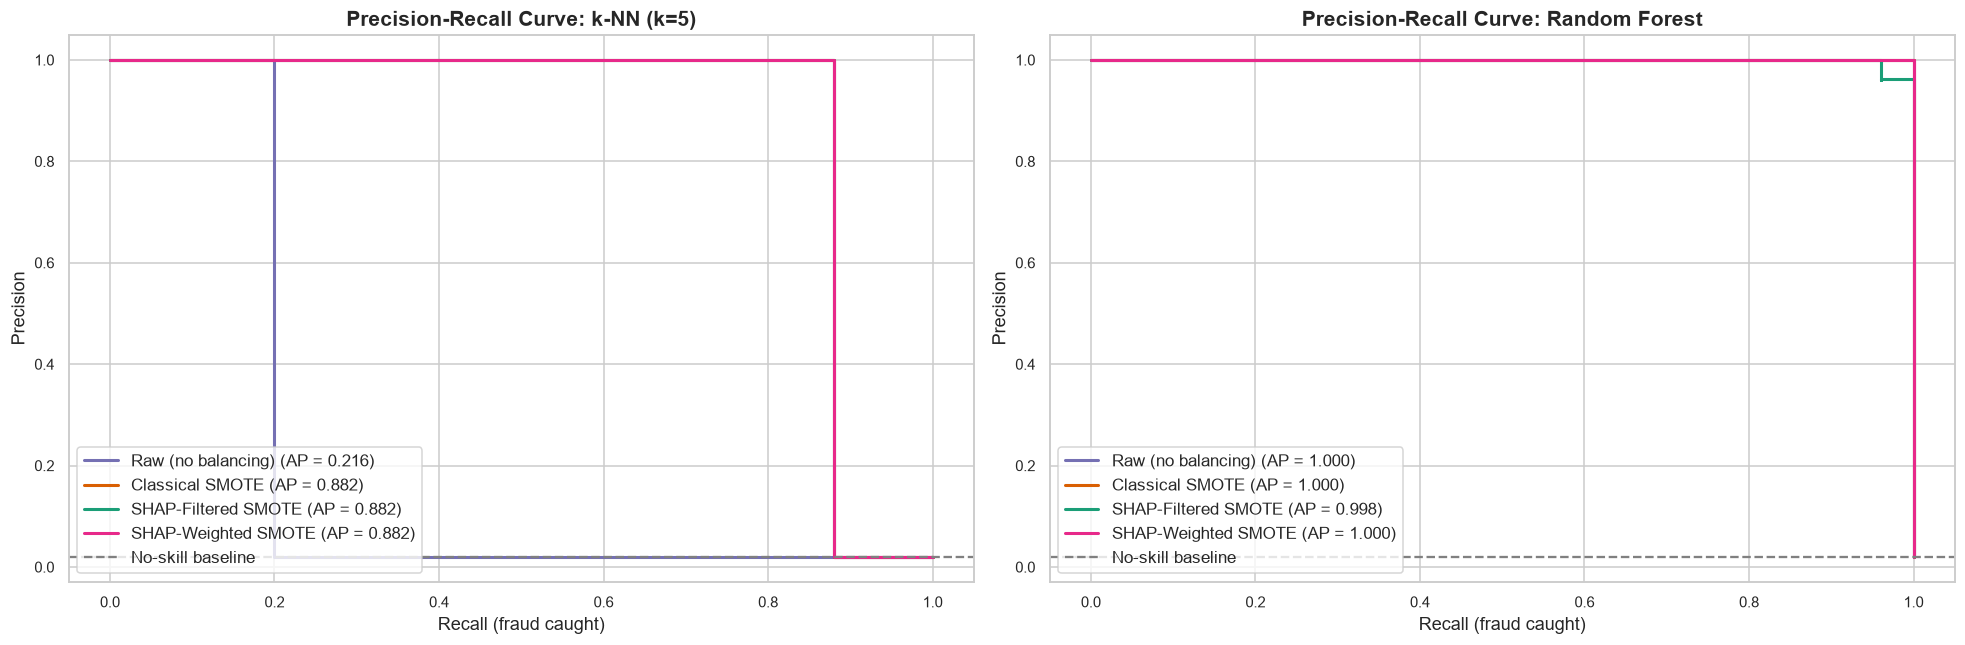

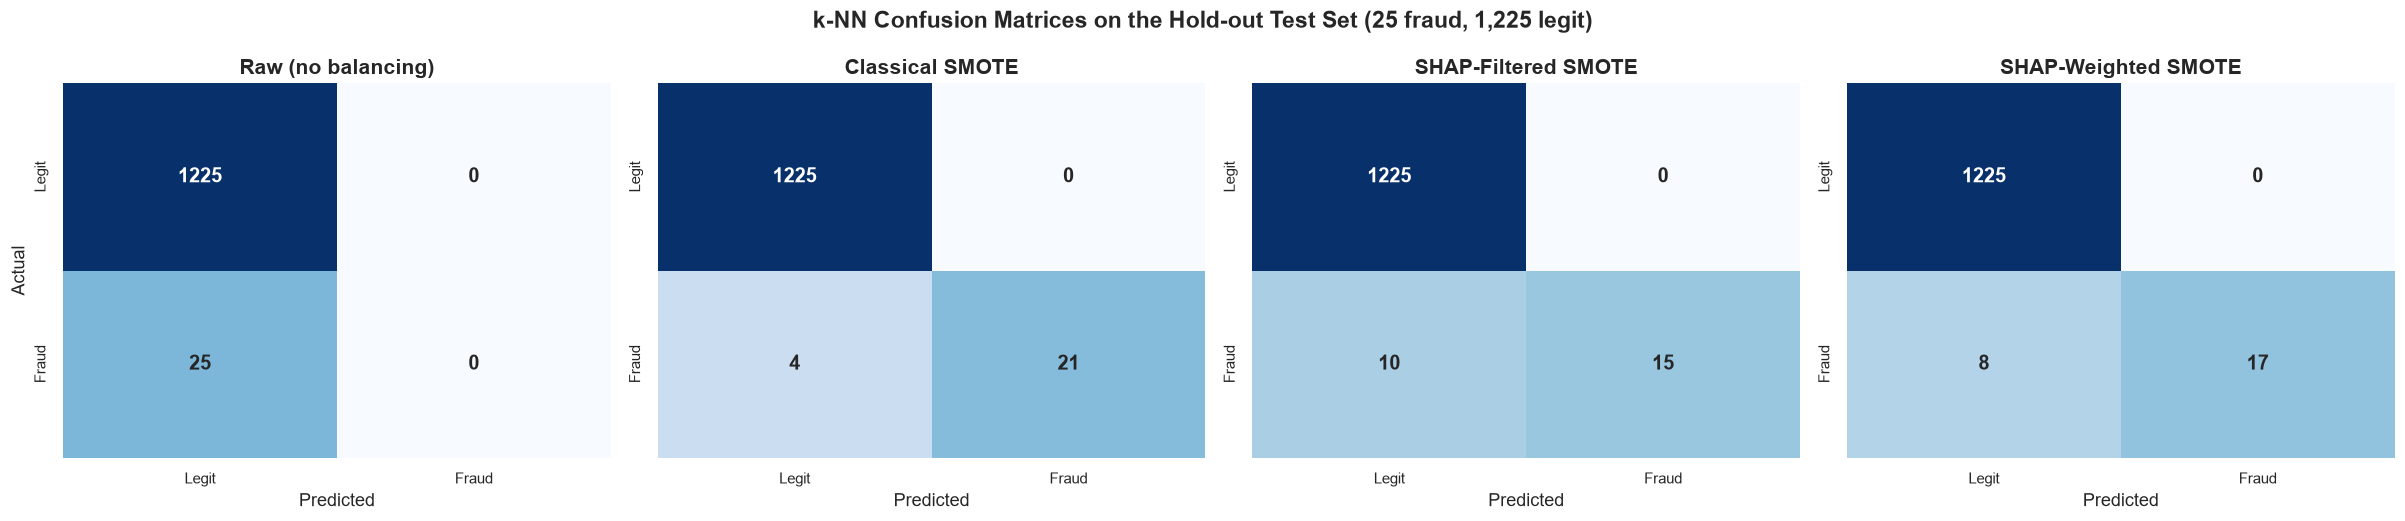

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, c in zip(axes, CLASSIFIERS):
    for m in METHODS:
        p = fitted[(m, c)].predict_proba(X_test_s)[:, 1]
        prec, rec, _ = precision_recall_curve(y_test, p)
        ap = df_holdout.query('Method == @m and Classifier == @c')['pr_auc'].iloc[0]
        ax.plot(rec, prec, color=METHOD_COLORS[m], linewidth=2, drawstyle='steps-post', label=f'{m} (AP = {ap:.3f})')
    ax.axhline(y_test.mean(), color='gray', linestyle='--', label='No-skill baseline')
    ax.set_title(f'Precision-Recall Curve: {c}', fontweight='bold')
    ax.set_xlabel('Recall (fraud caught)')
    ax.set_ylabel('Precision')
    ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
for ax, m in zip(axes, METHODS):
    cm = confusion_matrix(y_test, fitted[(m, 'k-NN (k=5)')].predict(X_test_s))
    sns.heatmap(np.log1p(cm), annot=cm, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'], annot_kws={'fontsize': 13, 'fontweight': 'bold'})
    ax.set_title(m, fontweight='bold')
    ax.set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
plt.suptitle('k-NN Confusion Matrices on the Hold-out Test Set (25 fraud, 1,225 legit)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

> **Key Takeaway:** Without balancing, k-NN never predicts fraud (0 of 25 caught), so oversampling is essential for distance-based models. Random Forest is near-perfect with or without balancing. With only 25 test frauds, one or two cases change the ranking, so Section 12 checks the result with repeated cross-validation.

## 12. Repeated Leak-Free Cross-Validation (2% and 1% Fraud)
Each fold wraps the full chain in `LeakFreePipeline`: scaler → SHAP attribution → oversampling → classifier, all fit
inside the training fold. We use 5 folds × 2 repeats. We then repeat the experiment with **1% fraud** (99:1), because
real card fraud is often rarer than 2%.

In [22]:
def leak_free_cv(X_all, y_all, n_splits=5, n_repeats=2):
    records = []
    folds = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=SEED)
    for fold, (tr, te) in enumerate(folds.split(X_all, y_all)):
        for m, s in samplers.items():
            for c, make in CLASSIFIERS.items():
                pipe = LeakFreePipeline(oversampler=clone(s), classifier=make()).fit(X_all[tr], y_all[tr])
                records.append({'Fold': fold, 'Fraud Rate': f'{y_all.mean():.0%}', 'Classifier': c, 'Method': m,
                                **evaluate_multi_dimensional_metrics(pipe, X_all[te], y_all[te])})
    return pd.DataFrame(records)

X_rare, y_rare, _ = load_benchmark_dataset('credit_fraud', random_state=SEED, n_samples=5000, minority_ratio=0.01)
df_cv = pd.concat([leak_free_cv(X, y), leak_free_cv(X_rare, y_rare)], ignore_index=True)

df_cv_summary = df_cv.groupby(['Fraud Rate', 'Classifier', 'Method'], sort=False)[
    ['pr_auc', 'minority_recall', 'minority_precision', 'minority_f1', 'ece']].agg(['mean', 'std']).round(3)
display(df_cv_summary)

pr_auc        minority_recall  \
                                               mean    std            mean   
Fraud Rate Classifier    Method                                              
2%         k-NN (k=5)    Raw (no balancing)   0.358  0.125           0.000   
           Random Forest Raw (no balancing)   0.997  0.004           0.930   
           k-NN (k=5)    Classical SMOTE      0.809  0.094           0.735   
           Random Forest Classical SMOTE      1.000  0.000           1.000   
           k-NN (k=5)    SHAP-Filtered SMOTE  0.814  0.072           0.750   
           Random Forest SHAP-Filtered SMOTE  0.999  0.003           0.995   
           k-NN (k=5)    SHAP-Weighted SMOTE  0.844  0.079           0.770   
           Random Forest SHAP-Weighted SMOTE  0.998  0.007           0.995   
1%         k-NN (k=5)    Raw (no balancing)   0.218  0.098           0.000   
           Random Forest Raw (no balancing)   0.989  0.016           0.790   
           k-NN (k=5)    Classical SMOTE      0.682  0.112           0.650   
           Random Forest Classical SMOTE      0.939  0.039           0.590   
           k-NN (k=5)    SHAP-Filtered SMOTE  0.751  0.085           0.650   
           Random Forest SHAP-Filtered SMOTE  0.946  0.043           0.590   
           k-NN (k=5)    SHAP-Weighted SMOTE  0.720  0.122           0.690   
           Random Forest SHAP-Weighted SMOTE  0.945  0.035           0.580   

                                                    minority_precision         \
                                                std               mean    std   
Fraud Rate Classifier    Method                                                 
2%         k-NN (k=5)    Raw (no balancing)   0.000              0.000  0.000   
           Random Forest Raw (no balancing)   0.063              0.985  0.024   
           k-NN (k=5)    Classical SMOTE      0.088              1.000  0.000   
           Random Forest Classical SMOTE      0.000              0.981  0.032   
           k-NN (k=5)    SHAP-Filtered SMOTE  0.091              1.000  0.000   
           Random Forest SHAP-Filtered SMOTE  0.016              0.962  0.037   
           k-NN (k=5)    SHAP-Weighted SMOTE  0.059              0.988  0.026   
           Random Forest SHAP-Weighted SMOTE  0.016              0.977  0.033   
1%         k-NN (k=5)    Raw (no balancing)   0.000              0.000  0.000   
           Random Forest Raw (no balancing)   0.088              1.000  0.000   
           k-NN (k=5)    Classical SMOTE      0.143              1.000  0.000   
           Random Forest Classical SMOTE      0.191              1.000  0.000   
           k-NN (k=5)    SHAP-Filtered SMOTE  0.127              1.000  0.000   
           Random Forest SHAP-Filtered SMOTE  0.152              1.000  0.000   
           k-NN (k=5)    SHAP-Weighted SMOTE  0.137              1.000  0.000   
           Random Forest SHAP-Weighted SMOTE  0.155              0.958  0.089   

                                             minority_f1           ece         
                                                    mean    std   mean    std  
Fraud Rate Classifier    Method                                                
2%         k-NN (k=5)    Raw (no balancing)        0.000  0.000  0.018  0.001  
           Random Forest Raw (no balancing)        0.955  0.031  0.010  0.001  
           k-NN (k=5)    Classical SMOTE           0.845  0.058  0.006  0.002  
           Random Forest Classical SMOTE           0.990  0.017  0.030  0.002  
           k-NN (k=5)    SHAP-Filtered SMOTE       0.854  0.062  0.006  0.001  
           Random Forest SHAP-Filtered SMOTE       0.978  0.024  0.029  0.001  
           k-NN (k=5)    SHAP-Weighted SMOTE       0.864  0.039  0.005  0.001  
           Random Forest SHAP-Weighted SMOTE       0.985  0.017  0.028  0.002  
1%         k-NN (k=5)    Raw (no balancing)        0.000  0.000  0.010  0.000  
           Random Forest Raw (no balancing)        0.880  0.05

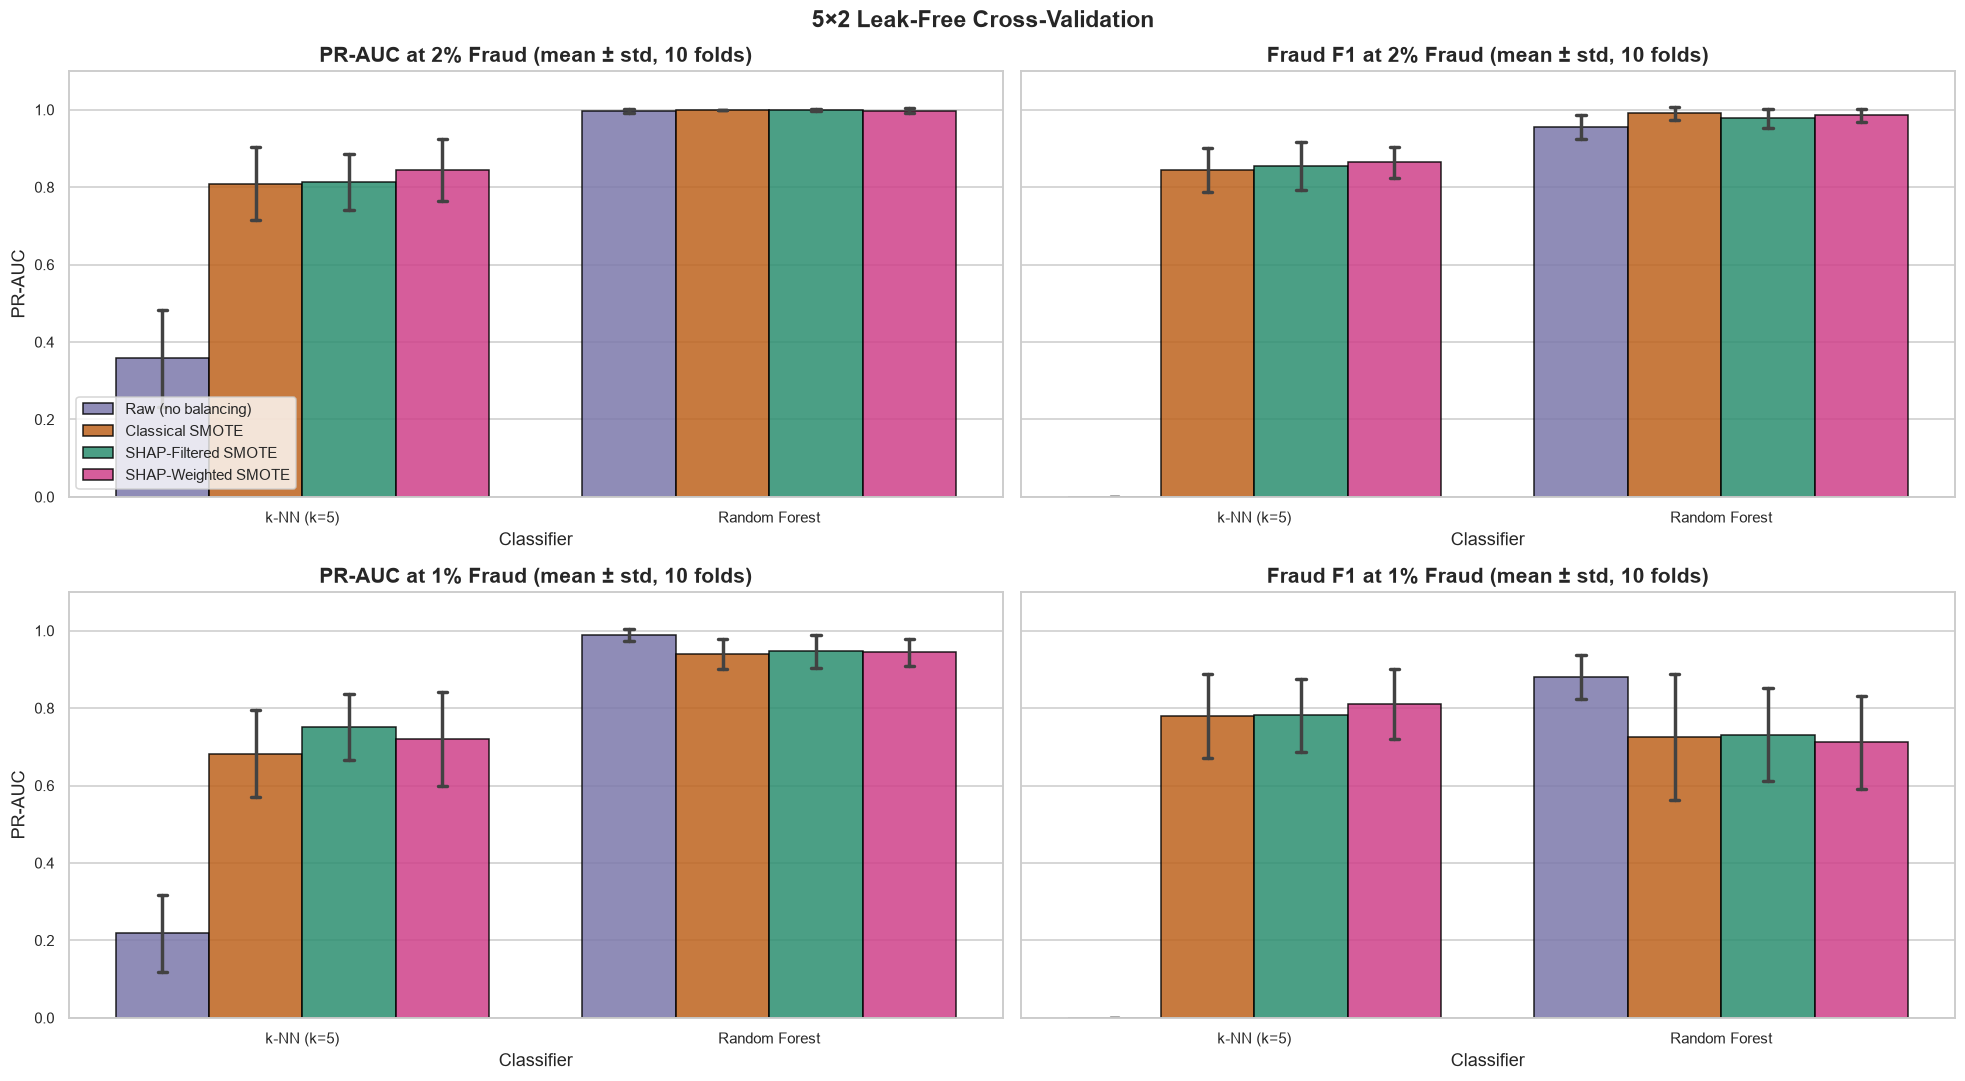

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(18, 10), sharey=True)
for row, rate in enumerate(['2%', '1%']):
    for col, (metric, label) in enumerate([('pr_auc', 'PR-AUC'), ('minority_f1', 'Fraud F1')]):
        ax = axes[row, col]
        sns.barplot(data=df_cv[df_cv['Fraud Rate'] == rate], x='Classifier', y=metric, hue='Method', hue_order=METHODS,
                    palette=METHOD_COLORS, errorbar='sd', capsize=0.08, edgecolor='black', alpha=0.85, ax=ax)
        ax.set_title(f'{label} at {rate} Fraud (mean ± std, 10 folds)', fontweight='bold')
        ax.set_ylabel(label)
        ax.set_ylim(0, 1.1)
        if (row, col) != (0, 0):
            ax.get_legend().remove()
axes[0, 0].legend(loc='lower left', fontsize=10)
plt.suptitle('5×2 Leak-Free Cross-Validation', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

> **Key Takeaway:** For k-NN, SHAP-guided SMOTE beats Classical SMOTE at both fraud rates: PR-AUC 0.81 → 0.84 (SHAP-Weighted) at 2%, and 0.68 → 0.75 (SHAP-Filtered) at 1%. The gains are about one fold-to-fold standard deviation, so they are consistent but modest. For Random Forest at 1% fraud, **every oversampler lowers F1** (0.88 raw → about 0.72), so oversampling is not a free win for tree ensembles.

## 13. Summary of Findings: What SHAP-SMOTE Changed

In [24]:
cv_means = df_cv.groupby(['Fraud Rate', 'Classifier', 'Method'])[['pr_auc', 'minority_f1']].mean()
df_summary = pd.DataFrame({
    'Train Samples': df_counts.set_index('Method')['Train Samples'],
    'Fraud Samples': df_counts.set_index('Method')['Minority (1)'],
    'k-NN Features': df_counts.set_index('Method')['k-NN Features'],
    'Sign Agreement (%)': df_neigh.set_index('Method')['Sign Agreement (%)'],
    'Oracle Label Noise (%)': df_fidelity['Oracle Label Noise (%)'],
    'CV PR-AUC k-NN (2%)': cv_means.loc[('2%', 'k-NN (k=5)'), 'pr_auc'],
    'CV PR-AUC k-NN (1%)': cv_means.loc[('1%', 'k-NN (k=5)'), 'pr_auc'],
    'CV F1 RF (2%)': cv_means.loc[('2%', 'Random Forest'), 'minority_f1'],
    'CV F1 RF (1%)': cv_means.loc[('1%', 'Random Forest'), 'minority_f1'],
}).reindex(METHODS).round(3)
display(df_summary)

,Train Samples,Fraud Samples,k-NN Features,Sign Agreement (%),Oracle Label Noise (%),CV PR-AUC k-NN (2%),CV PR-AUC k-NN (1%),CV F1 RF (2%),CV F1 RF (1%)
Method,,,,,,,,,
Raw (no balancing),3750,75,-,NaN,NaN,0.358,0.218,0.955,0.880
Classical SMOTE,7350,3675,28 (equal weight),79.010,3.194,0.809,0.682,0.990,0.725
SHAP-Filtered SMOTE,7350,3675,7 (SHAP subspace),80.533,3.444,0.814,0.751,0.978,0.732
SHAP-Weighted SMOTE,7350,3675,28 (SHAP-weighted),79.771,2.722,0.844,0.720,0.985,0.711


| Pipeline Step | What Changed in the Data | Evidence |
|---|---|---|
| **Data Quality Audit** | Nothing removed: 0 missing, 0 infinite, 0 duplicate, 0 constant | Section 2 |
| **Outlier Handling** | Outliers flagged, not deleted: 100% of fraud rows are outliers | Section 3 |
| **Leak-Free Split & Scaling** | Stratified 75/25 split; scaler fit on train only (test mean ≠ 0 exactly) | Section 5 |
| **SHAP Attribution** | 7/7 hidden fraud components ranked top, holding about 90% of the weight | Section 6 |
| **SHAP-Filtered SMOTE** | k-NN restricted to the 7 SHAP-selected components; 75 → 3,675 fraud | Sections 7–8 |
| **SHAP-Weighted SMOTE** | Fraud axes stretched about 2×, noise axes shrunk to about 0.35×; 75 → 3,675 fraud | Sections 7–8 |
| **Synthetic Placement** | Fewer synthetic frauds in the legit centre (about 10% → 6% on the top component) | Section 9 |
| **Synthetic Realism** | Lowest oracle label noise with SHAP-Weighted (2.72% vs 3.19%) | Section 10 |
| **Downstream (k-NN)** | PR-AUC +0.03 (2% fraud) to +0.07 (1% fraud) over Classical SMOTE | Section 12 |
| **Downstream (Random Forest)** | Already near-perfect; at 1% fraud oversampling lowers F1 | Section 12 |

---
**Conclusion:** On this simulation SHAP correctly identifies the fraud signal and SHAP-SMOTE uses it: neighbour
search moves into the predictive subspace and fewer synthetic frauds land in legit territory. The downstream gains are
consistent for distance-based models but modest, because in this data the fraud signal already dominates plain Euclidean
distance. Larger gains are expected when many noisy or large-scale components dominate the distance.

## 14. Real Data: ULB / Kaggle Credit Card Fraud (284,807 Transactions)
Sections 1–13 used the simulator because it has a known ground truth. From here on we run the same pipeline on the
**real** dataset ([Kaggle `mlg-ulb/creditcardfraud`](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud), mirrored on
OpenML as dataset 1597): 284,807 European card transactions from September 2013, 492 of them fraud (0.17%).

The file is read from `data/credit_card/creditcard.csv`. If it is missing, it is downloaded from OpenML and saved there.
The OpenML copy has `V1`–`V28` (PCA components), `Amount`, and `Class`; it does not include Kaggle's `Time` column.

In [2]:
CC_DIR = REPO_ROOT / 'data' / 'credit_card'
CC_CSV = CC_DIR / 'creditcard.csv'
if not CC_CSV.exists():
    from sklearn.datasets import fetch_openml
    CC_DIR.mkdir(parents=True, exist_ok=True)
    cc_raw = fetch_openml(data_id=1597, as_frame=True, parser='auto').frame
    cc_raw['Class'] = cc_raw['Class'].astype(int)
    cc_raw.to_csv(CC_CSV, index=False)

cc = pd.read_csv(CC_CSV)
CC_FEATURES = [c for c in cc.columns if c != 'Class']
cc_num = cc[CC_FEATURES]

df_cc_quality = pd.DataFrame([
    {'Check': 'Missing cells', 'Count': int(cc_num.isna().sum().sum())},
    {'Check': 'Infinite cells', 'Count': int(np.isinf(cc_num.values).sum())},
    {'Check': 'Duplicate rows', 'Count': int(cc.duplicated().sum())},
    {'Check': 'Duplicate fraud rows', 'Count': int(cc[cc.Class == 1].duplicated().sum())},
    {'Check': 'Constant columns', 'Count': int((cc_num.nunique() <= 1).sum())},
])
display(df_cc_quality)

cc_clean = cc.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates().reset_index(drop=True)
cc_counts = pd.DataFrame({
    'Rows': [len(cc), len(cc_clean)],
    'Legit (0)': [int((cc.Class == 0).sum()), int((cc_clean.Class == 0).sum())],
    'Fraud (1)': [int((cc.Class == 1).sum()), int((cc_clean.Class == 1).sum())],
}, index=['Raw file', 'After cleaning'])
cc_counts['Fraud %'] = (cc_counts['Fraud (1)'] / cc_counts['Rows'] * 100).map('{:.3f}%'.format)
display(cc_counts)
display(cc_clean.head())

NameError: name 'REPO_ROOT' is not defined

## 15. Leak-Free Split and SHAP Attribution on the Real Data
Same rules as Section 5: stratified 75/25 split, `StandardScaler` fit on the training fold only. SHAP weights come from
the preliminary Random Forest on the scaled training fold.

In [ ]:
cc_X_train, cc_X_test, cc_y_train, cc_y_test = train_test_split(
    cc_clean[CC_FEATURES].values, cc_clean['Class'].values,
    test_size=0.25, stratify=cc_clean['Class'].values, random_state=SEED,
)
cc_scaler = StandardScaler().fit(cc_X_train)
cc_X_train_s, cc_X_test_s = cc_scaler.transform(cc_X_train), cc_scaler.transform(cc_X_test)

cc_weights, cc_masv, _ = compute_masv_weights(cc_X_train_s, cc_y_train, random_state=SEED)
df_cc_masv = pd.DataFrame({'Feature': CC_FEATURES, 'MASV': cc_masv, 'Weight_w': cc_weights})
df_cc_masv = df_cc_masv.sort_values('MASV', ascending=False).reset_index(drop=True)
df_cc_masv['Cumulative_Weight'] = df_cc_masv['Weight_w'].cumsum()
print(f'Train fold: {len(cc_y_train):,} rows ({int(cc_y_train.sum())} fraud) | '
      f'Test fold: {len(cc_y_test):,} rows ({int(cc_y_test.sum())} fraud)')
display(df_cc_masv.head(10).round(4))

## 16. Generating the Rebalanced Datasets
Each oversampler is fit on the scaled training fold. Its synthetic fraud rows are mapped back to the original units
(`scaler.inverse_transform`), so the output has the same columns and scale as `creditcard.csv`, plus two columns:
- `is_synthetic`: `0` for a real transaction, `1` for a row created by the oversampler
- `method`: the oversampler that produced the file

`TARGET_RATIO = 1.0` balances fraud 1:1 with legit (the same setting as Sections 7–12). Lower it (e.g. `0.1`) for smaller files.

In [ ]:
TARGET_RATIO = 1.0
OUT_DIR = CC_DIR / 'generated'
OUT_DIR.mkdir(parents=True, exist_ok=True)
strategy = 'auto' if TARGET_RATIO == 1.0 else TARGET_RATIO

cc_samplers = {
    'Classical SMOTE': ClassicalSMOTE(sampling_strategy=strategy, k_neighbors=5, random_state=SEED),
    'SHAP-Filtered SMOTE': SHAPFilteredSMOTE(sampling_strategy=strategy, cumulative_threshold=0.90, k_neighbors=5, random_state=SEED),
    'SHAP-Weighted SMOTE': SHAPWeightedSMOTE(sampling_strategy=strategy, k_neighbors=5, random_state=SEED),
}

def to_frame(X_scaled, y, is_synthetic, method):
    out = pd.DataFrame(cc_scaler.inverse_transform(X_scaled), columns=CC_FEATURES)
    out['Class'] = y.astype(int)
    out['is_synthetic'] = is_synthetic
    out['method'] = method
    return out

n_cc_train = len(cc_y_train)
generated, gen_records = {}, []
for name, s in cc_samplers.items():
    Xr, yr = s.fit_resample(cc_X_train_s, cc_y_train)
    # Every sampler appends its synthetic rows after the original rows
    flag = np.r_[np.zeros(n_cc_train, dtype=int), np.ones(len(yr) - n_cc_train, dtype=int)]
    generated[name] = to_frame(Xr, yr, flag, name)
    gen_records.append({
        'Method': name,
        'Real Legit': int((cc_y_train == 0).sum()),
        'Real Fraud': int((cc_y_train == 1).sum()),
        'Synthetic Fraud (new rows)': int(flag.sum()),
        'Total Rows': len(yr),
        'Fraud %': f'{yr.mean() * 100:.1f}%',
    })
display(pd.DataFrame(gen_records).set_index('Method'))

print('Sample of new synthetic fraud rows (SHAP-Weighted SMOTE, original units):')
display(generated['SHAP-Weighted SMOTE'].query('is_synthetic == 1').sample(8, random_state=SEED).round(4))

In [ ]:
files = {}
for name, frame in generated.items():
    slug = name.lower().replace(' ', '_').replace('-', '_')
    files[name] = OUT_DIR / f'creditcard_train_balanced_{slug}.csv'
    frame.to_csv(files[name], index=False, float_format='%.6f')

test_frame = to_frame(cc_X_test_s, cc_y_test, np.zeros(len(cc_y_test), dtype=int), 'Hold-out test (untouched)')
test_file = OUT_DIR / 'creditcard_test_holdout.csv'
test_frame.to_csv(test_file, index=False, float_format='%.6f')
files['Hold-out test'] = test_file

display(pd.DataFrame([{
    'Contents': name,
    'File': f.relative_to(REPO_ROOT).as_posix(),
    'Rows': len(generated[name]) if name in generated else len(test_frame),
    'Size (MB)': round(f.stat().st_size / 1e6, 1),
} for name, f in files.items()]))

## 17. Checking the Generated Files
We read every file back from disk and check it: real rows match the training fold exactly, every synthetic row is
labelled fraud, nothing is `NaN`, and synthetic values stay inside the range of the real fraud seeds (SMOTE only
interpolates, so it should never extrapolate). Then a Random Forest is trained on each file and scored on the untouched
hold-out file, to confirm the generated data is usable.

In [ ]:
real_fraud = cc_X_train[cc_y_train == 1]
fraud_lo, fraud_hi = real_fraud.min(0), real_fraud.max(0)

on_disk, check_records = {}, []
for name in cc_samplers:
    f = on_disk[name] = pd.read_csv(files[name])
    real, syn = f[f.is_synthetic == 0], f[f.is_synthetic == 1]
    syn_X = syn[CC_FEATURES].values
    check_records.append({
        'Method': name,
        'Rows on Disk': len(f),
        'Real Rows Match Train Fold': bool(np.allclose(real[CC_FEATURES].values, cc_X_train, atol=1e-5)),
        'Synthetic Labelled Fraud': bool((syn.Class == 1).all()),
        'NaN Cells': int(f[CC_FEATURES].isna().sum().sum()),
        'Synthetic Inside Real Fraud Range (%)': ((syn_X >= fraud_lo - 1e-5) & (syn_X <= fraud_hi + 1e-5)).all(1).mean() * 100,
    })
display(pd.DataFrame(check_records).set_index('Method'))

In [ ]:
test_df = pd.read_csv(test_file)
X_hold = cc_scaler.transform(test_df[CC_FEATURES].values)
y_hold = test_df['Class'].values

train_sets = {'Raw (no balancing)': (cc_X_train, cc_y_train)}
train_sets.update({name: (f[CC_FEATURES].values, f['Class'].values) for name, f in on_disk.items()})

cc_eval = []
for name, (Xf, yf) in train_sets.items():
    clf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED).fit(cc_scaler.transform(Xf), yf)
    cc_eval.append({'Method': name, 'Training Rows': len(yf), **evaluate_multi_dimensional_metrics(clf, X_hold, y_hold)})
df_cc_eval = pd.DataFrame(cc_eval).set_index('Method')
display(df_cc_eval[['Training Rows', 'pr_auc', 'roc_auc', 'minority_recall', 'minority_precision', 'minority_f1', 'ece']].round(3))

TAKEAWAY_PLACEHOLDER